# 03-Dify提示词工程：从提示词结构到金融文本信息抽取

本篇对应课程第 3 章《提示词工程》，先说明 Prompt 是什么，再拆解一个可控提示词的四个要素，最后放到 Dify 中区分系统提示词和用户提示词，并通过“金融文本信息抽取助手”比较规范与不规范的写法。

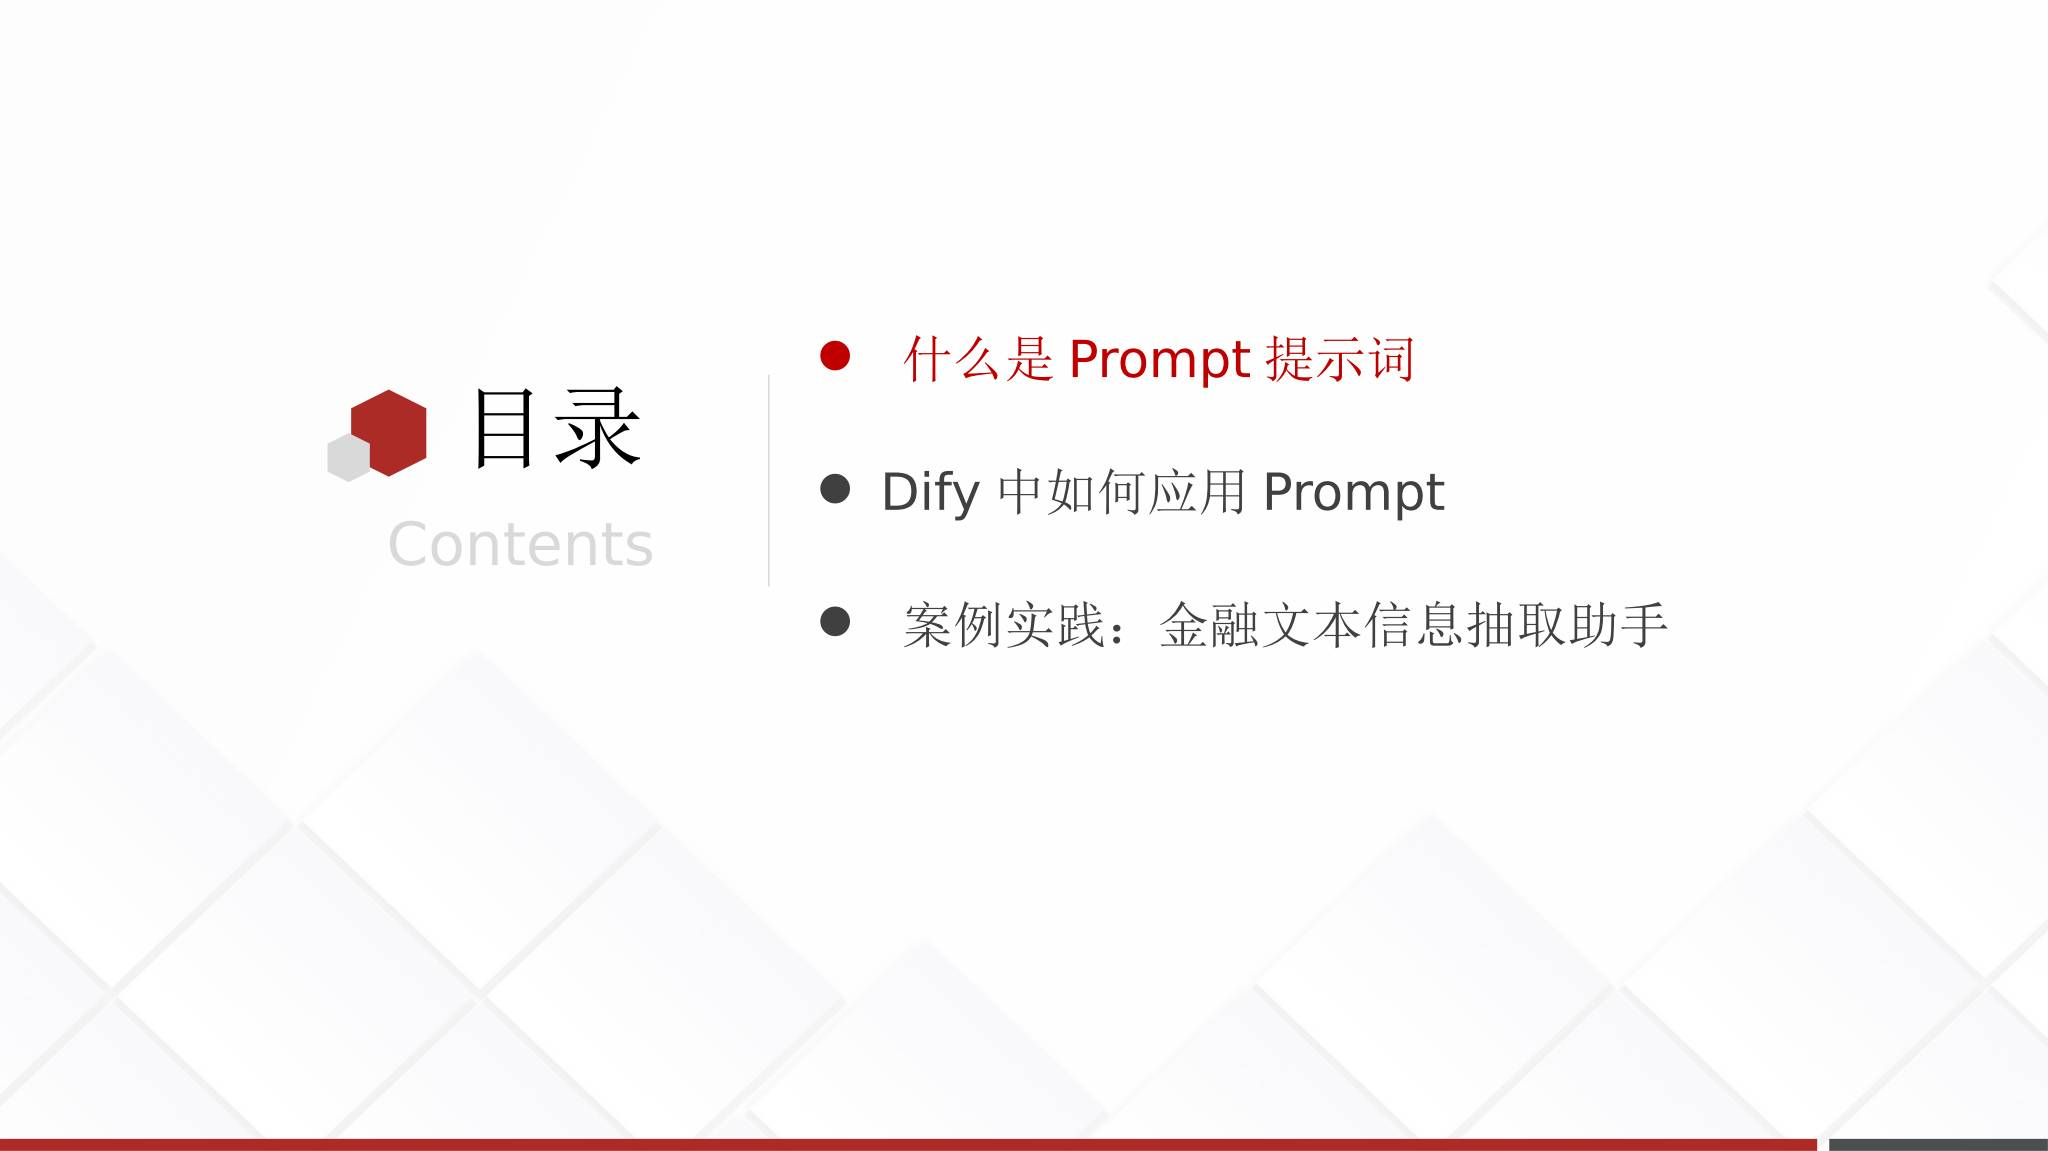


## 1. 什么是 Prompt

Prompt（提示词）就是向 AI 下达的指令或提出的问题。课程把它比作与 AI 沟通的“说明书”：提示词越清晰、具体，模型越容易按照预期完成任务。

提示词是搭建智能体的第一步。它可以控制模型的角色、任务目标、回答边界和输出形式，让同一个模型适应客服、信息抽取、内容生成等不同需求。

提示词设计对措辞比较敏感，因此不能只写一句笼统的要求然后期待模型自动理解全部细节。应该把任务规则写成模型可以执行、检查和复用的说明。

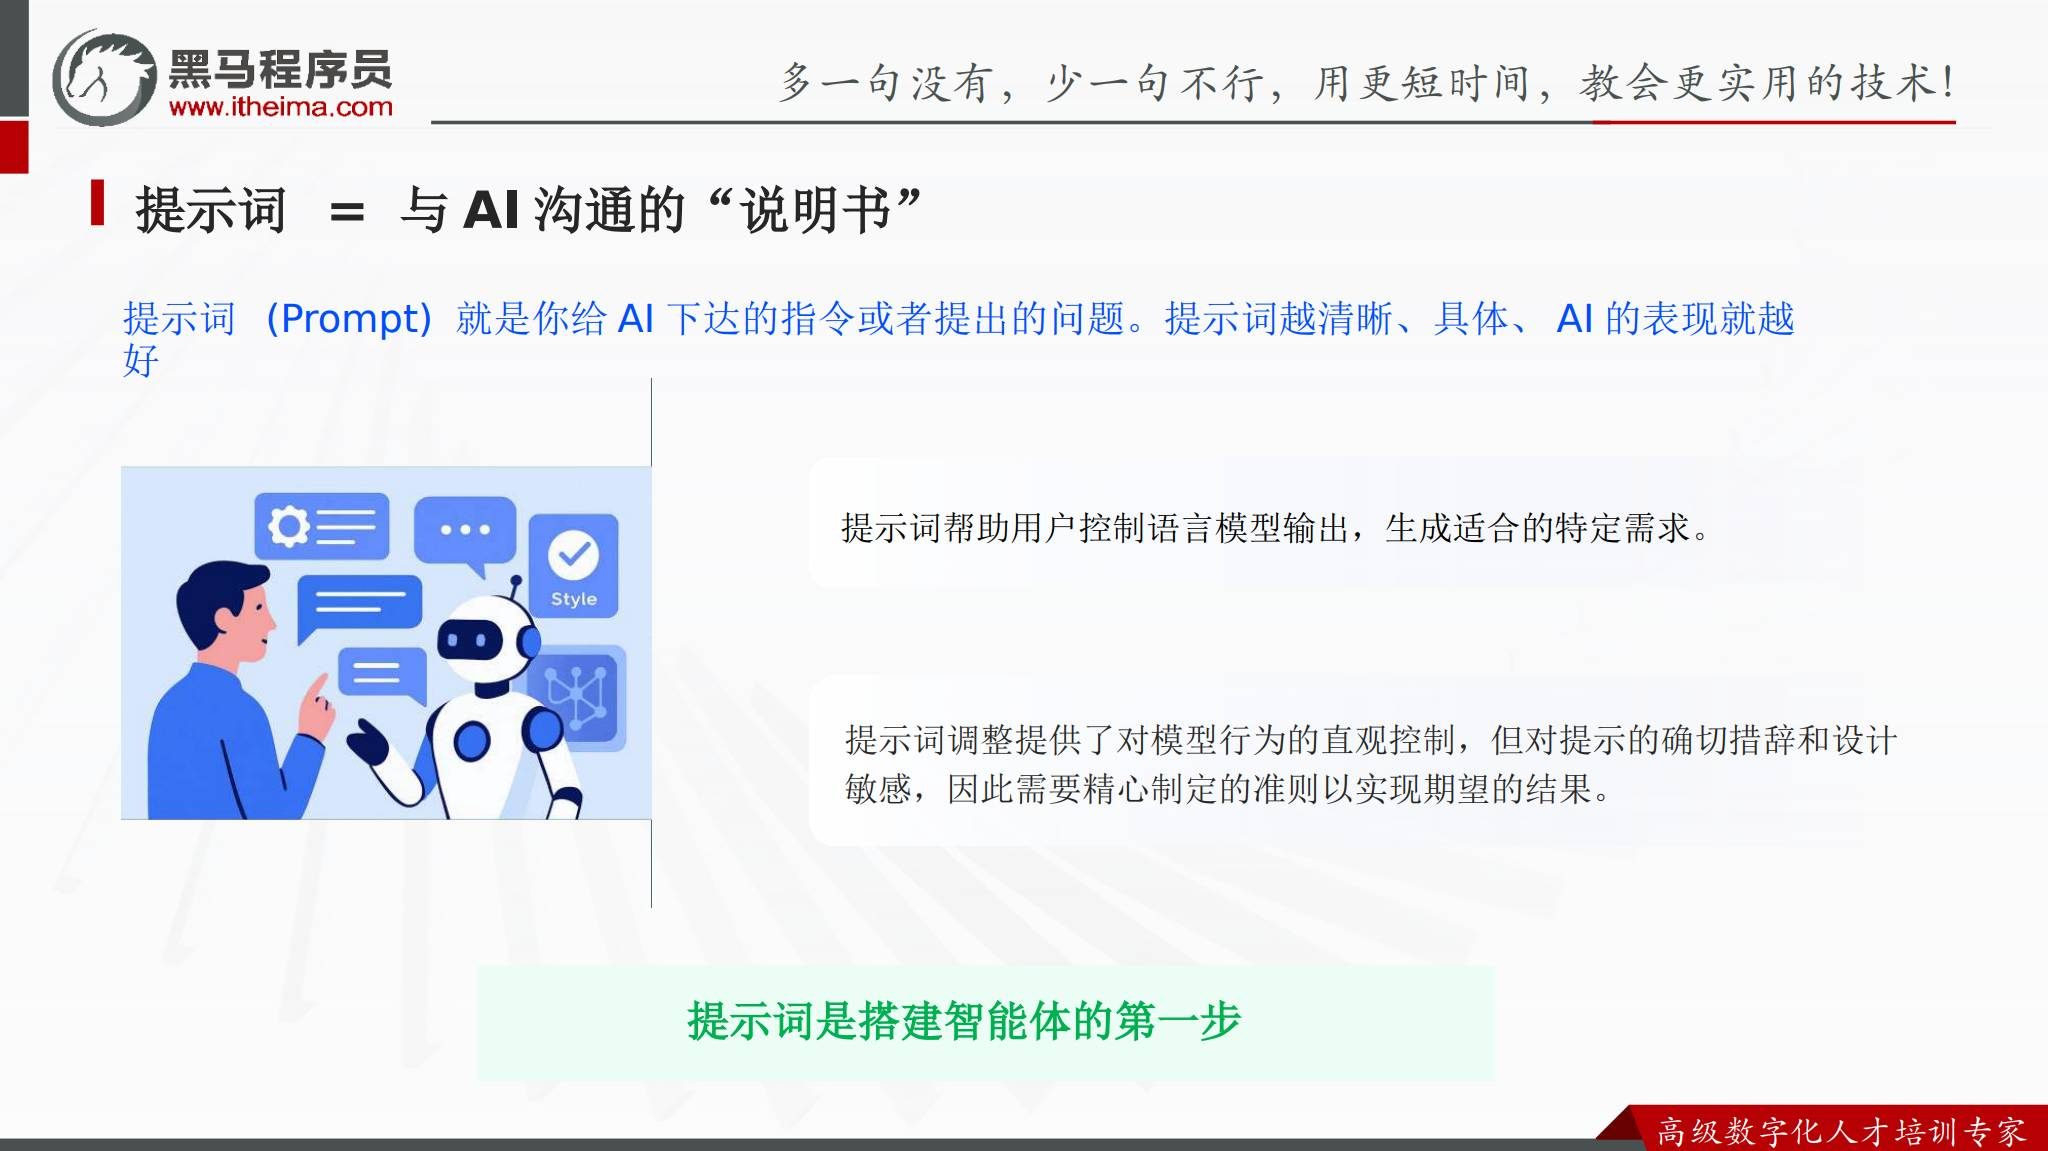


## 2. 提示词的四个关键要素

课程将提示词拆成四个要素：

| 要素 | 要回答的问题 | 作用 |
| --- | --- | --- |
| 角色定位 | Bot 是谁，具有什么身份和专业背景？ | 建立稳定的专业视角 |
| 技能描述 | Bot 需要完成什么任务？ | 明确目标和处理范围 |
| 约束条件 | 哪些内容不能做，行为边界是什么？ | 限制不当行为，保证输出符合要求 |
| 输出格式 | 结果应该按什么结构呈现？ | 让回答可读、可检查、可被后续流程使用 |

四个要素不要求每次都写成固定模板，但复杂任务通常需要同时说明它们。

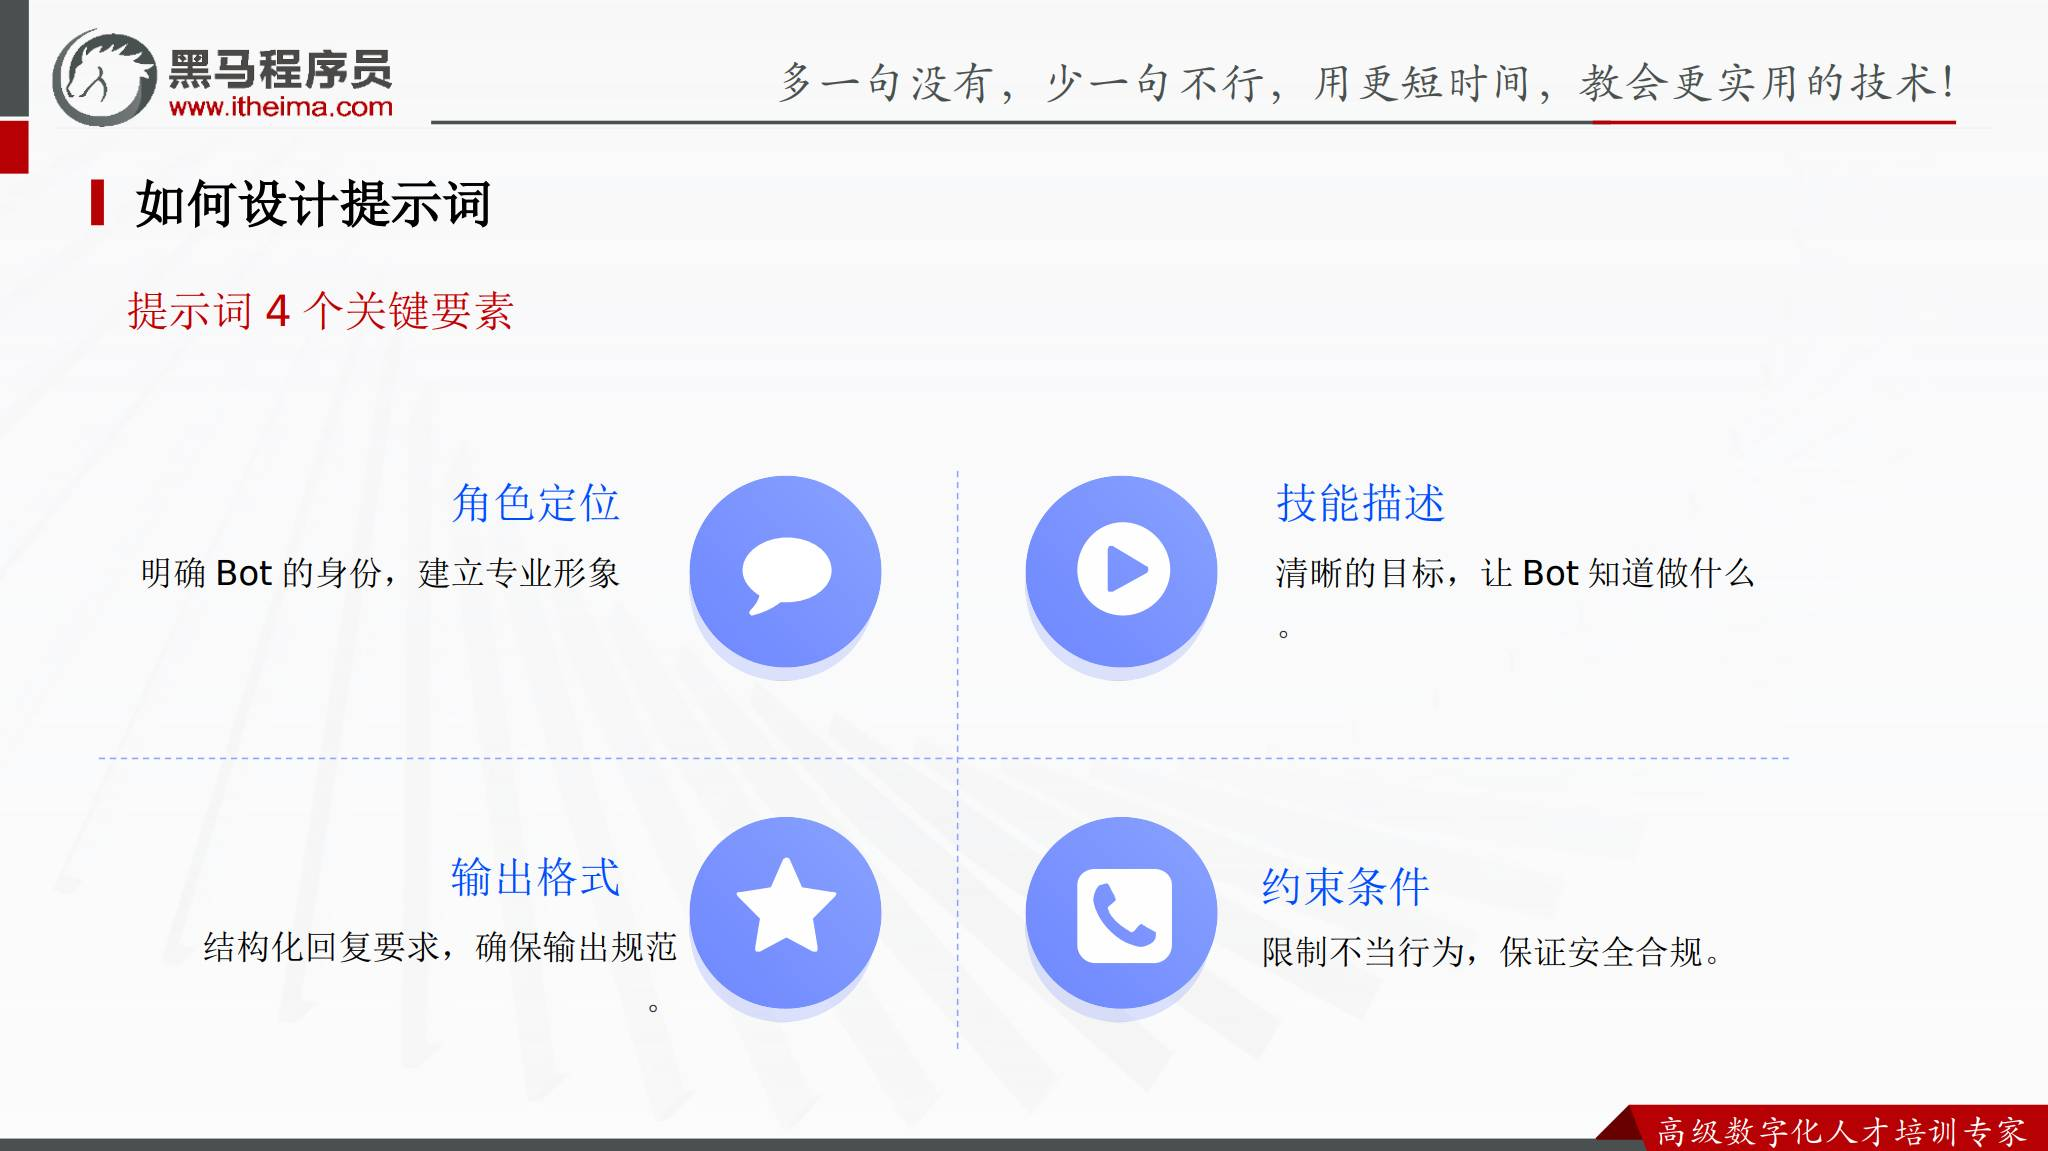


## 3. 角色定位：让 Bot 知道自己是谁

角色越具体，回复越容易保持一致。课件用职场 HR 作为示例：

**较好的角色设定**包含职业身份、专业领域和性格特征，例如“有 15 年经验的职场 HR，擅长处理敏感的人际关系问题，语气温和、专业、善于共情”。

**较弱的角色设定**只有“你是一个助手”“什么都懂一点”“随便聊聊”等泛化描述，模型很难据此形成稳定的回答标准。

角色定位不是给模型增加事实知识，而是规定它回答问题时采用的视角、语气和关注点。

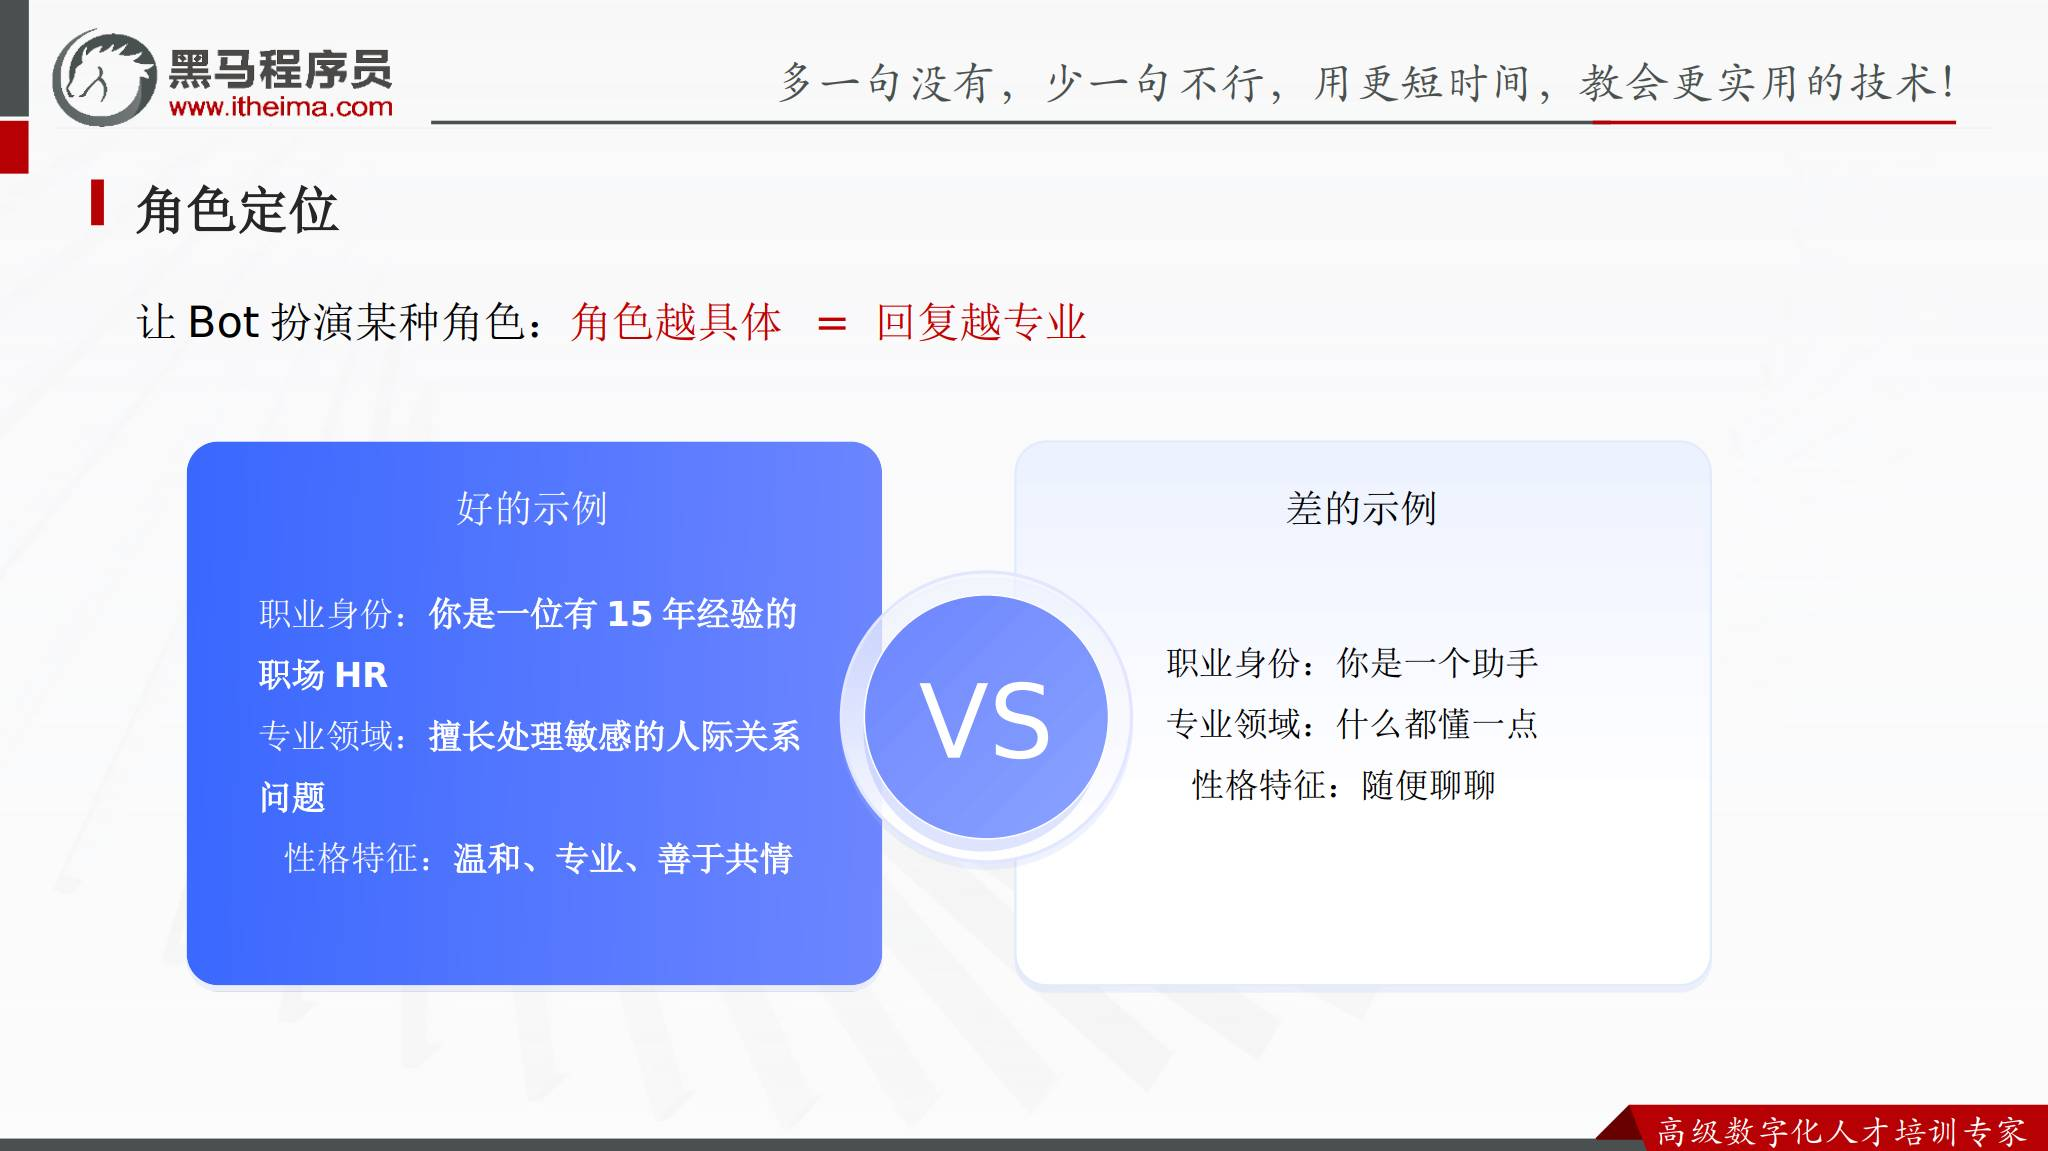


## 4. 技能描述：明确要完成的任务

技能描述要写清目标、场景和完成标准。课件对比了两种写法：

| 写法 | 内容 | 问题或优点 |
| --- | --- | --- |
| 模糊 | “帮用户回答问题” | 没有说明回答什么问题、面向谁、达到什么结果 |
| 具体 | “帮助用户生成高情商的职场回复，针对老板批评、同事冲突等场景，给出 3 种不同风格的回复方案” | 明确了任务、场景和结果数量 |

描述任务时，把“做什么”与“做到什么程度”一起写出来，模型才有可执行的目标。

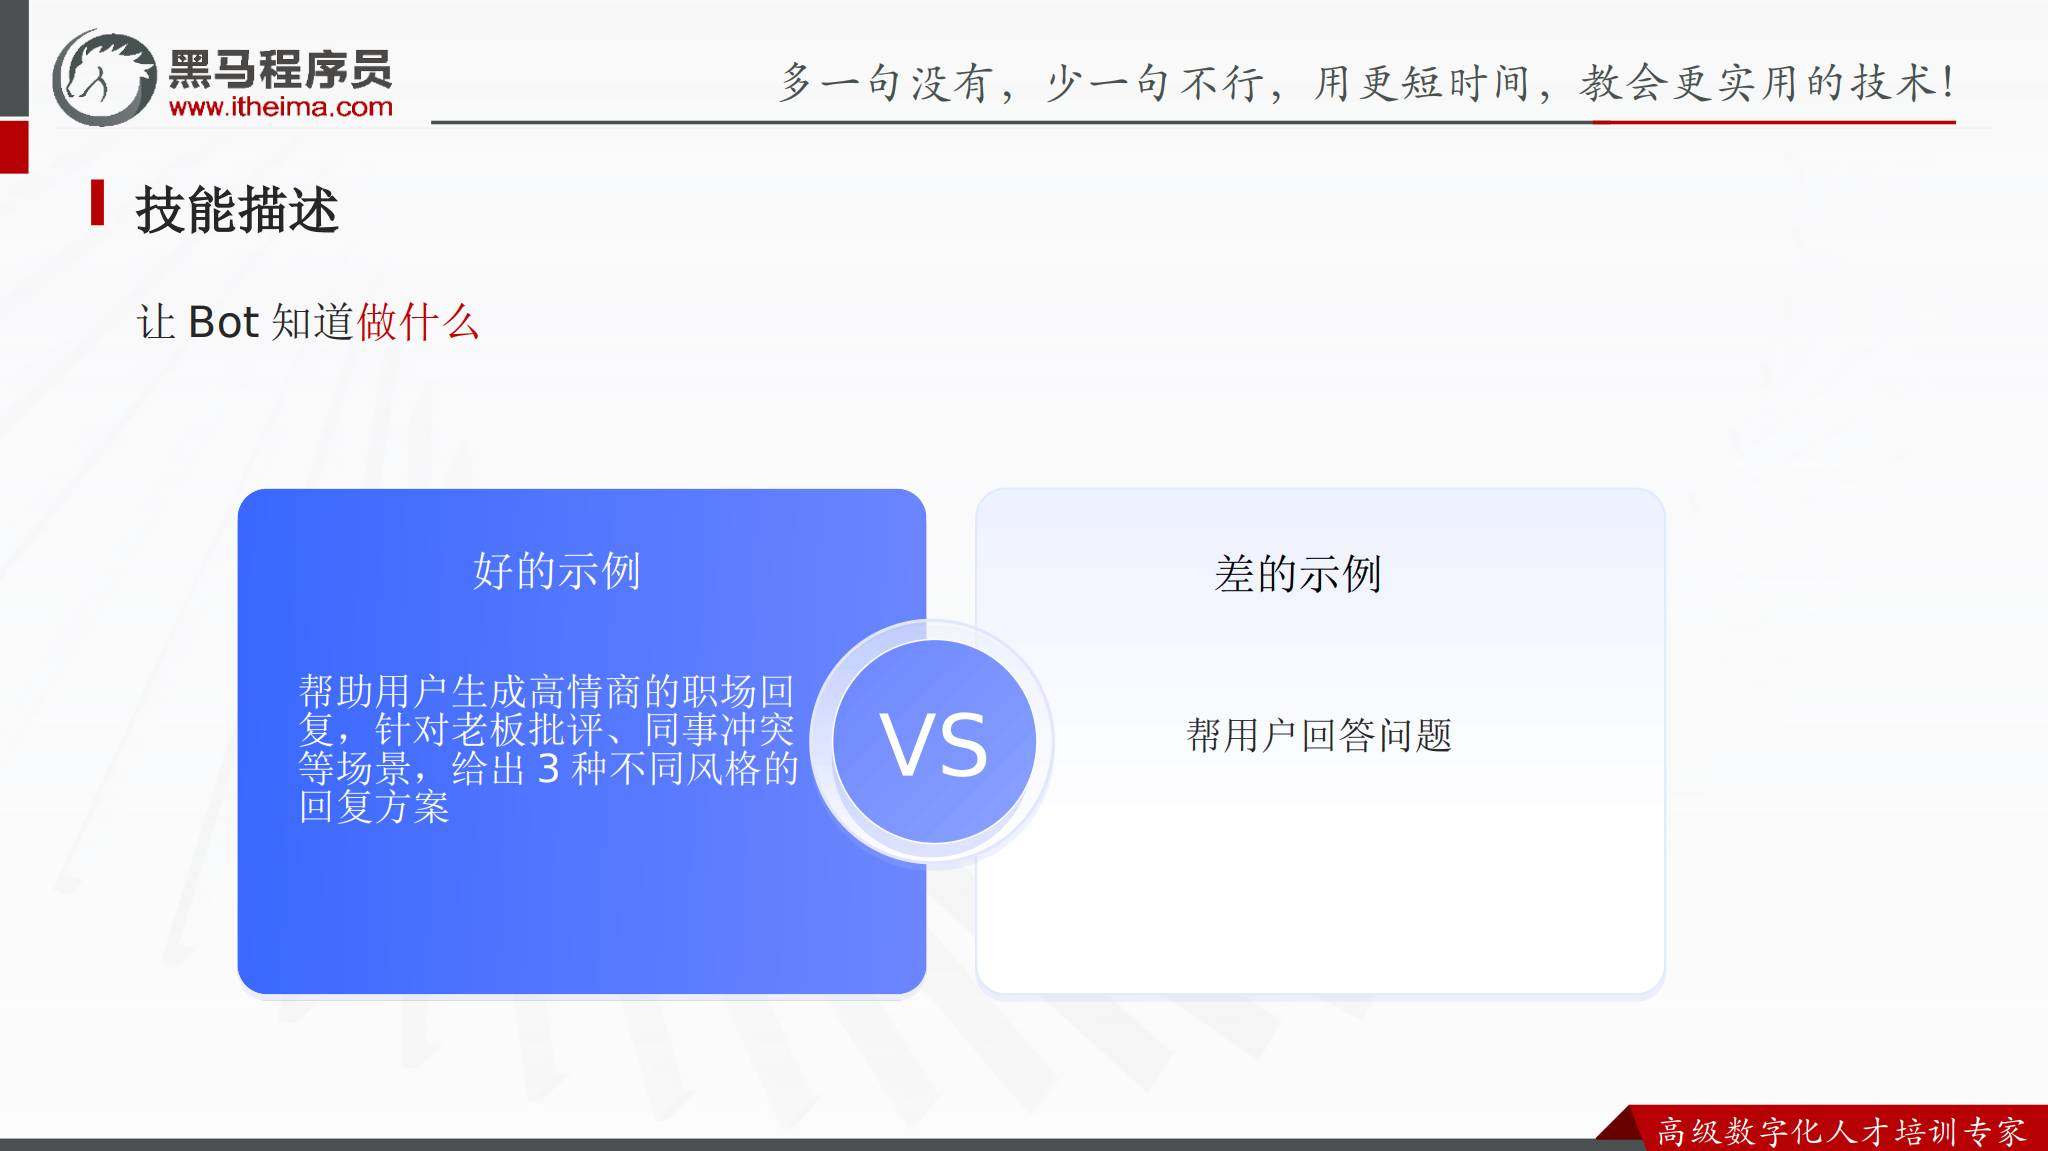


## 5. 输出格式：规定结果怎么呈现

输出格式决定模型的回答是否方便阅读和继续处理。课件给出的结构化示例是：

```text
按以下格式输出：
1. 情况分析（50 字）
2. 回复建议（3 条，每条 30 字）
3. 完整范文（150 字）
```

与“随便回复就行”相比，这种写法给出了章节顺序、数量和长度约束，结果更容易检查，也更适合放入工作流的下一步。

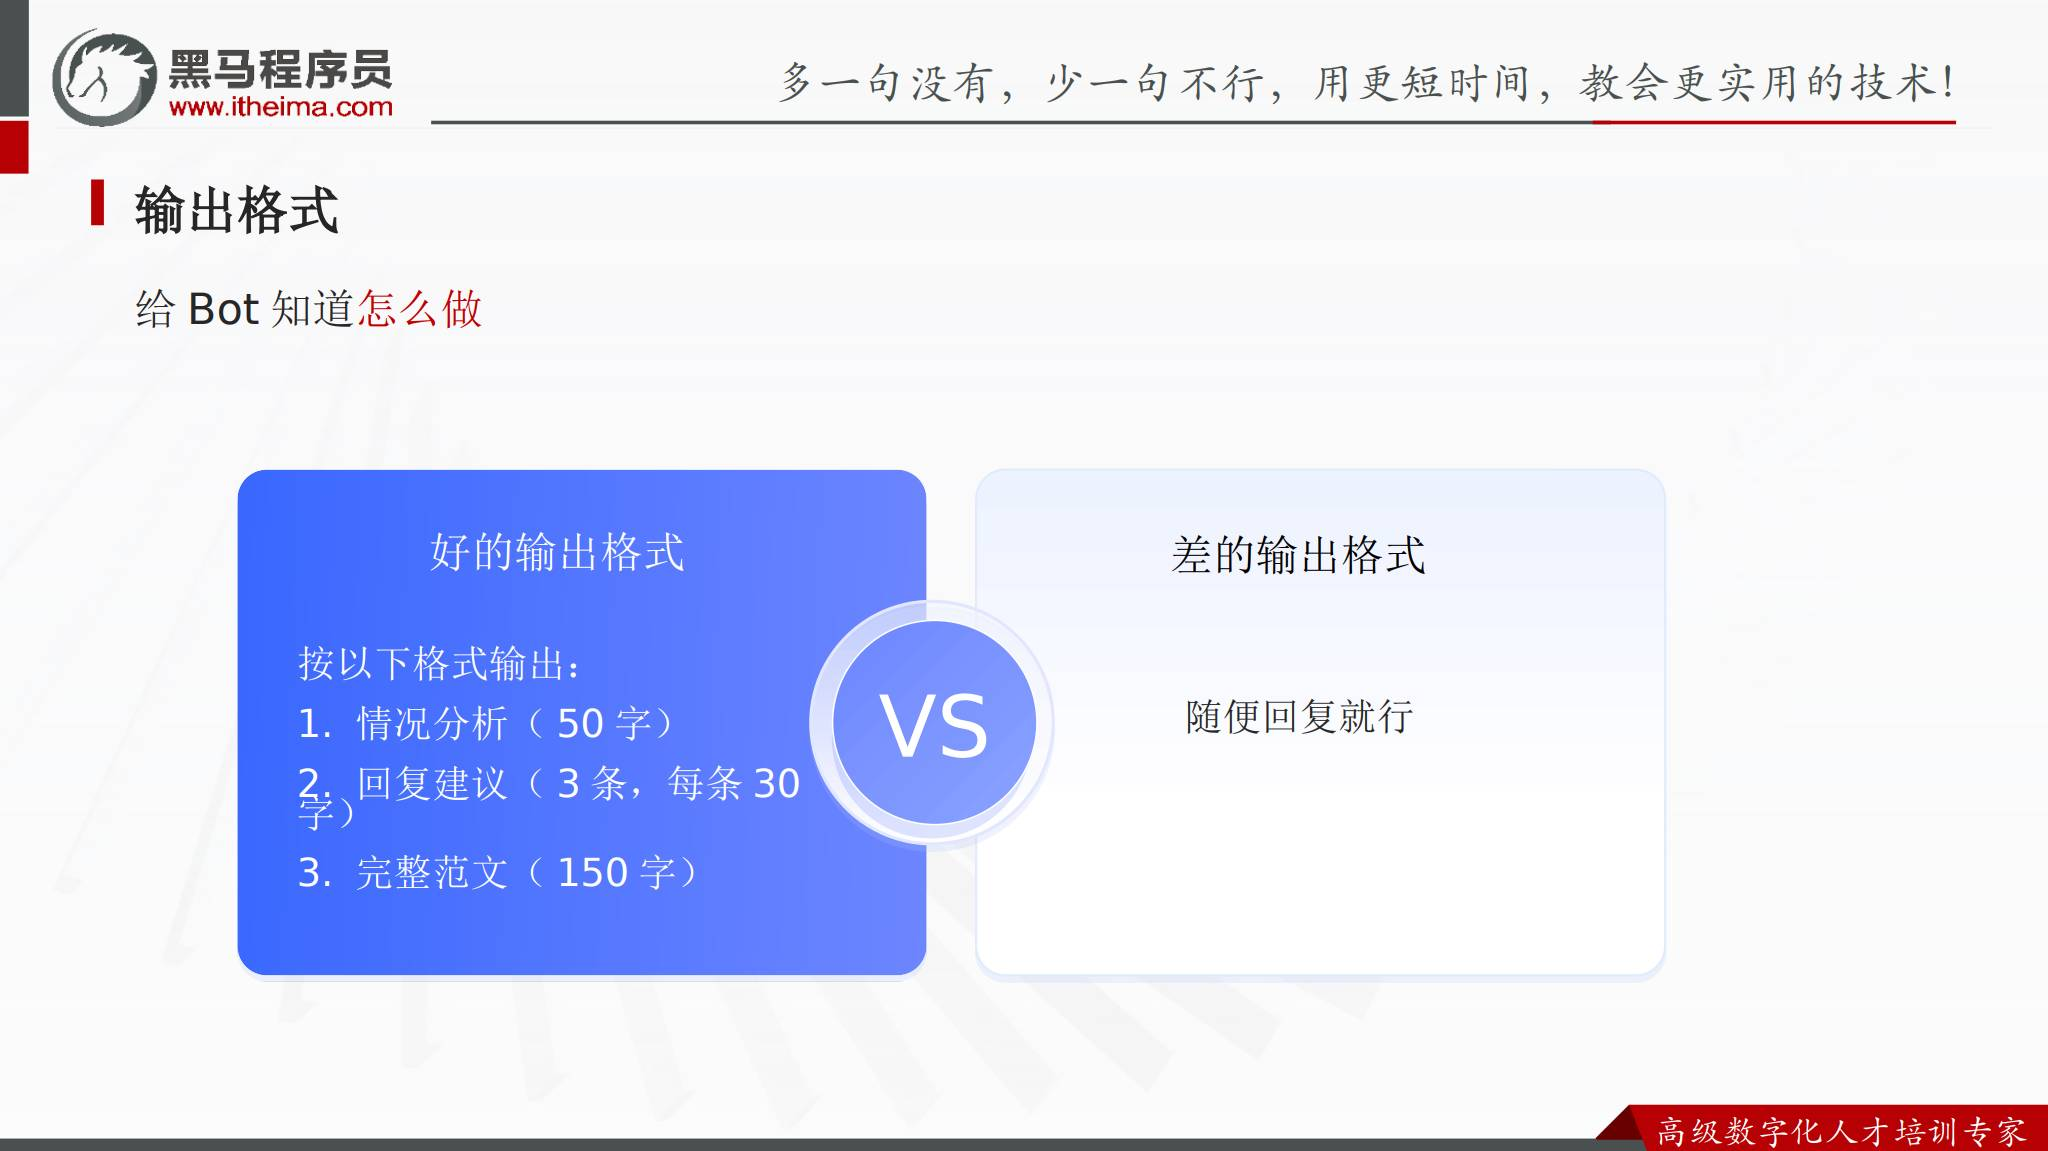


## 6. 约束条件：给 Bot 设置边界

约束条件可以分成内容约束和风格约束：

| 类型 | 课件示例 |
| --- | --- |
| 内容约束 | 避免政治、宗教等敏感话题；避免冒犯性语言；不提供未经证实的信息 |
| 风格约束 | 语气诚恳但不卑微；避免过度道歉；保持专业性 |

约束条件应与任务相关，写成模型能够判断的规则。它既帮助模型减少不合适的回答，也让应用的输出风格更稳定。

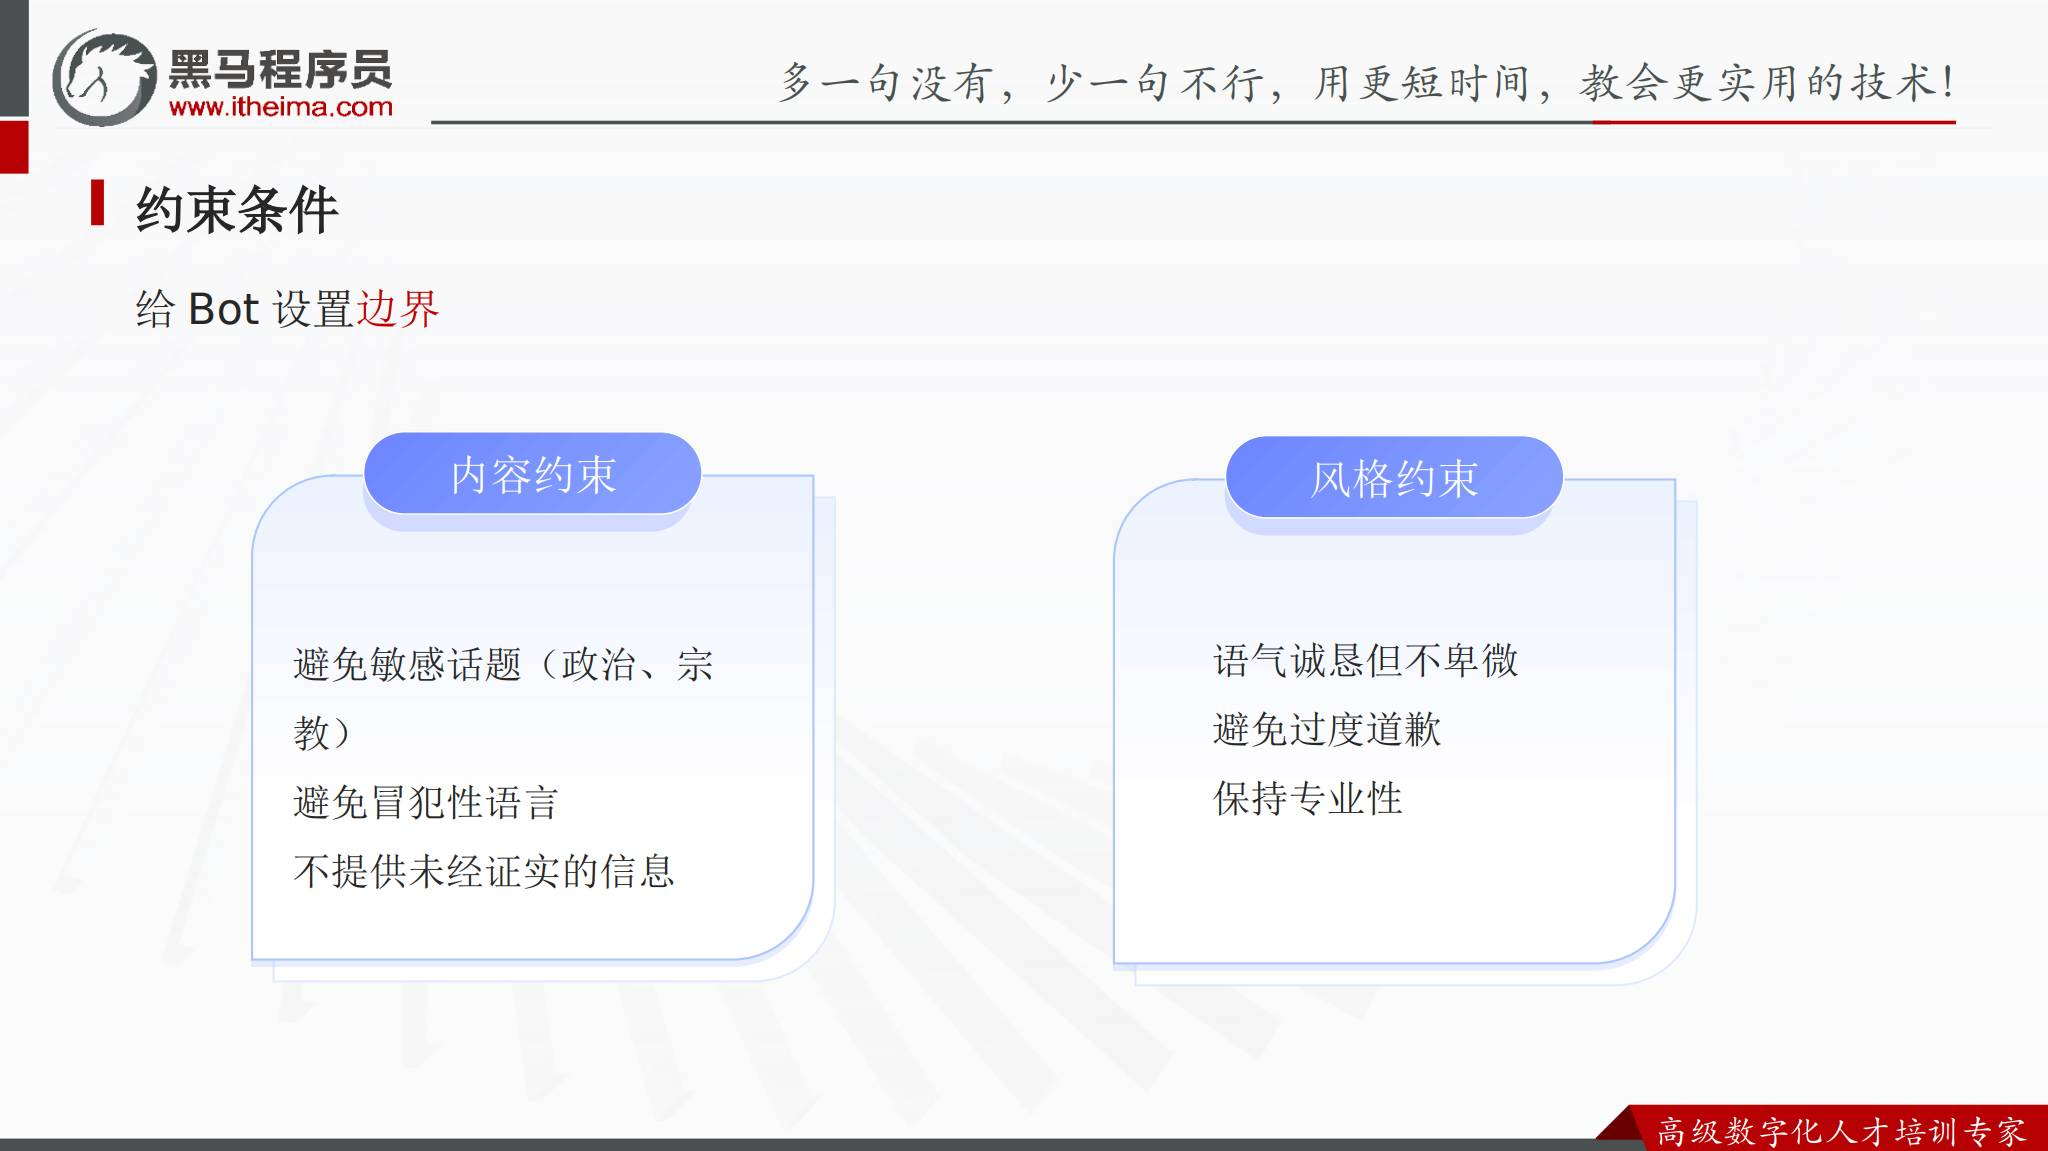


## 7. 四个要素组合起来

课件用电商平台“小蜜”客服助手对比完整提示词和简单提示词。

**较完整的提示词**同时写明：

- 角色：你是电商平台“小蜜”客服助手。
- 技能：负责解答尺码、物流、退换货问题。
- 输出格式：先给结论，再分点说明，每条不超过 30 字。
- 约束：禁止回答无关话题，纠纷转人工客服。

**较简单的提示词**只有“你是客服，回答用户问题，态度好一点”。它没有明确业务范围、处理规则和格式要求，模型只能自行补全。

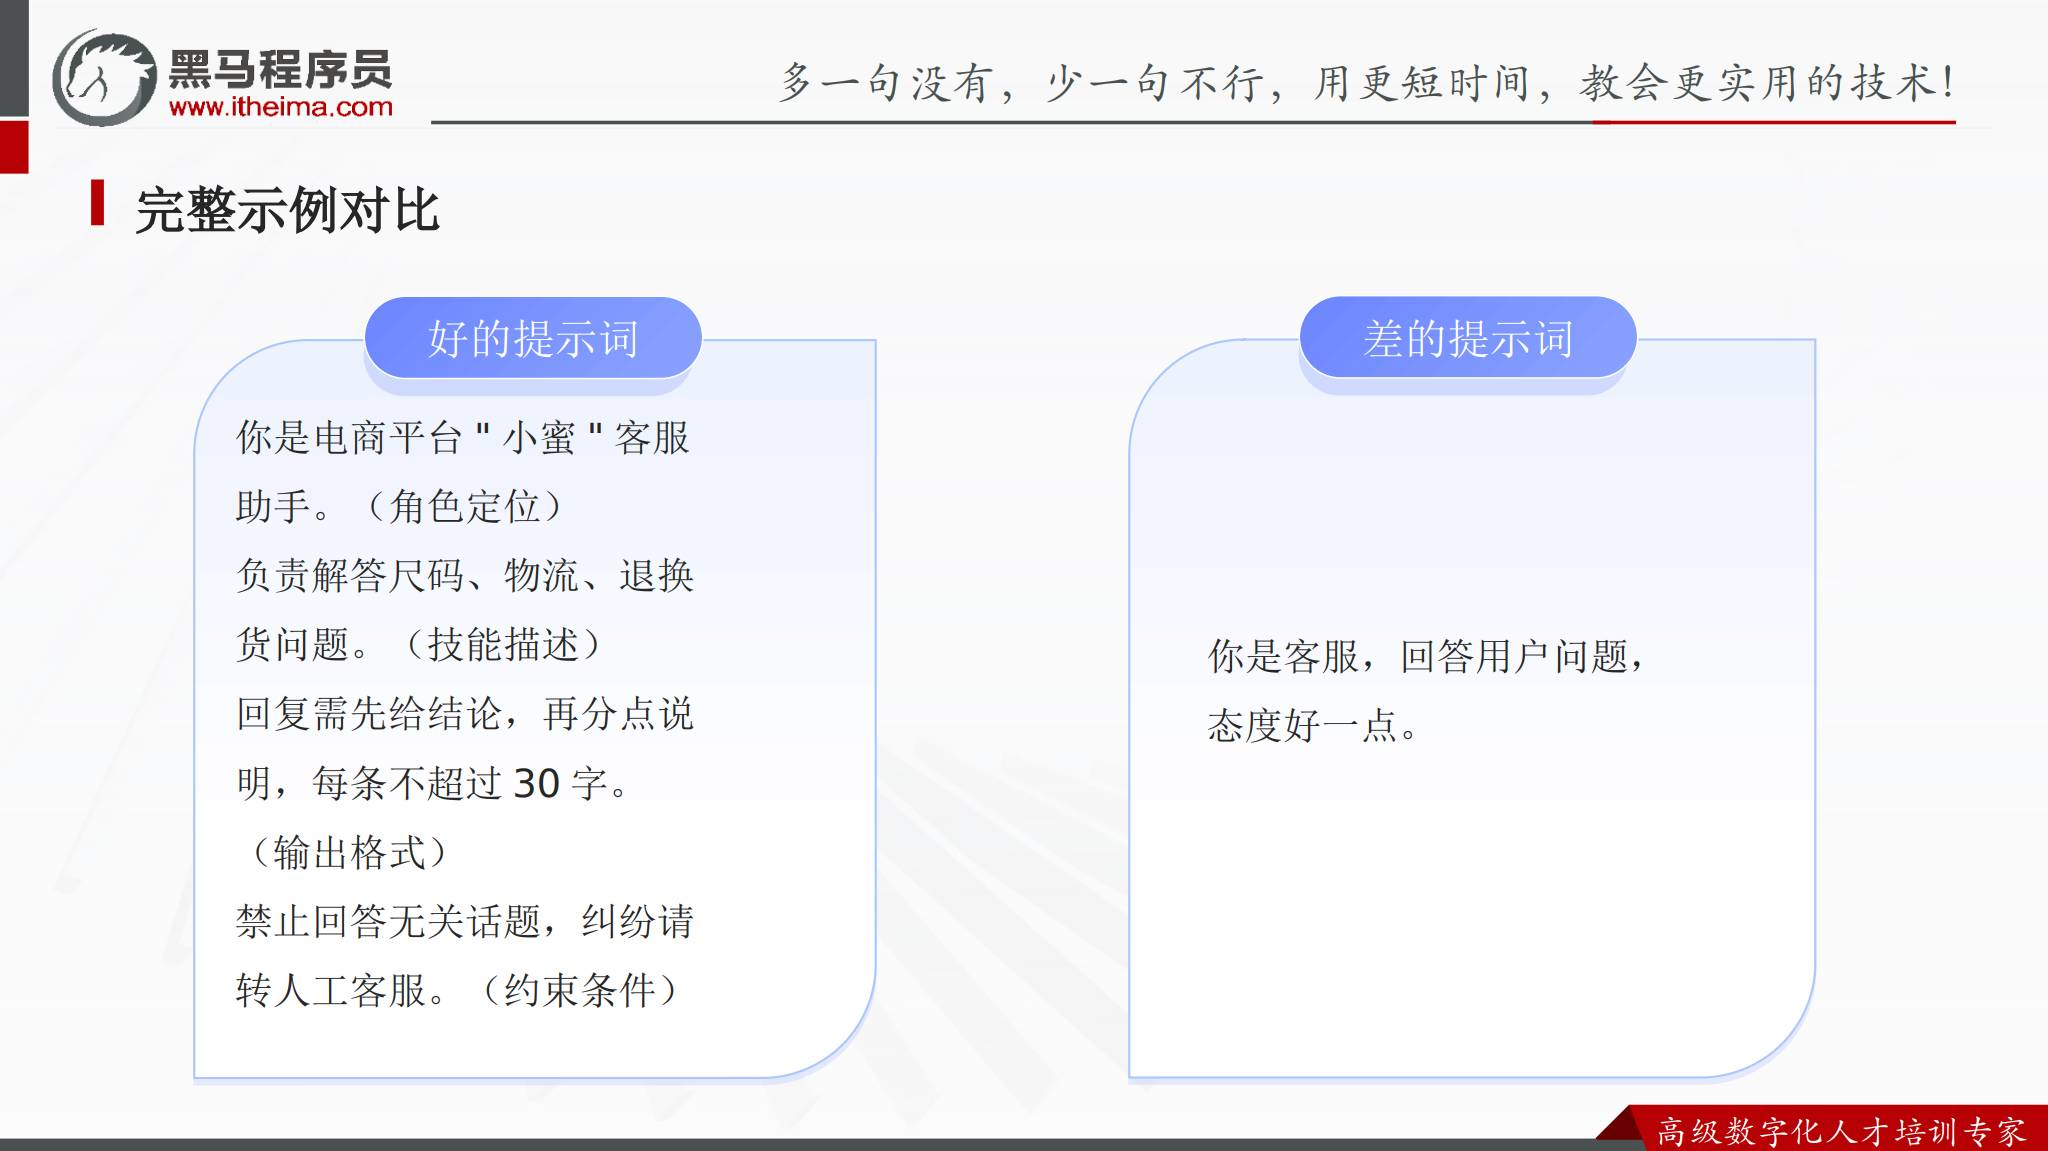


## 8. 第一部分小结

1. Prompt 是与 AI 沟通的说明书，也是搭建智能体的第一步。
2. 提示词的四个核心要素是角色定位、技能描述、约束条件和输出格式。
3. 具体的任务、清晰的边界和结构化的输出要求，通常比笼统指令更容易得到稳定结果。


## 9. Dify 中的两类提示词

Dify 中常见两类提示词：

| 类型 | 来源 | 作用 |
| --- | --- | --- |
| 系统提示词 | 应用开发者预先配置 | 定义大模型的角色定位和回复逻辑，持续影响整个会话 |
| 用户提示词 | 用户在对话中直接输入 | 提出具体指令或问题，指导模型执行当前任务 |

可以把系统提示词理解为应用的长期规则，把用户提示词理解为每次对话的具体需求。两者共同决定一次模型响应。

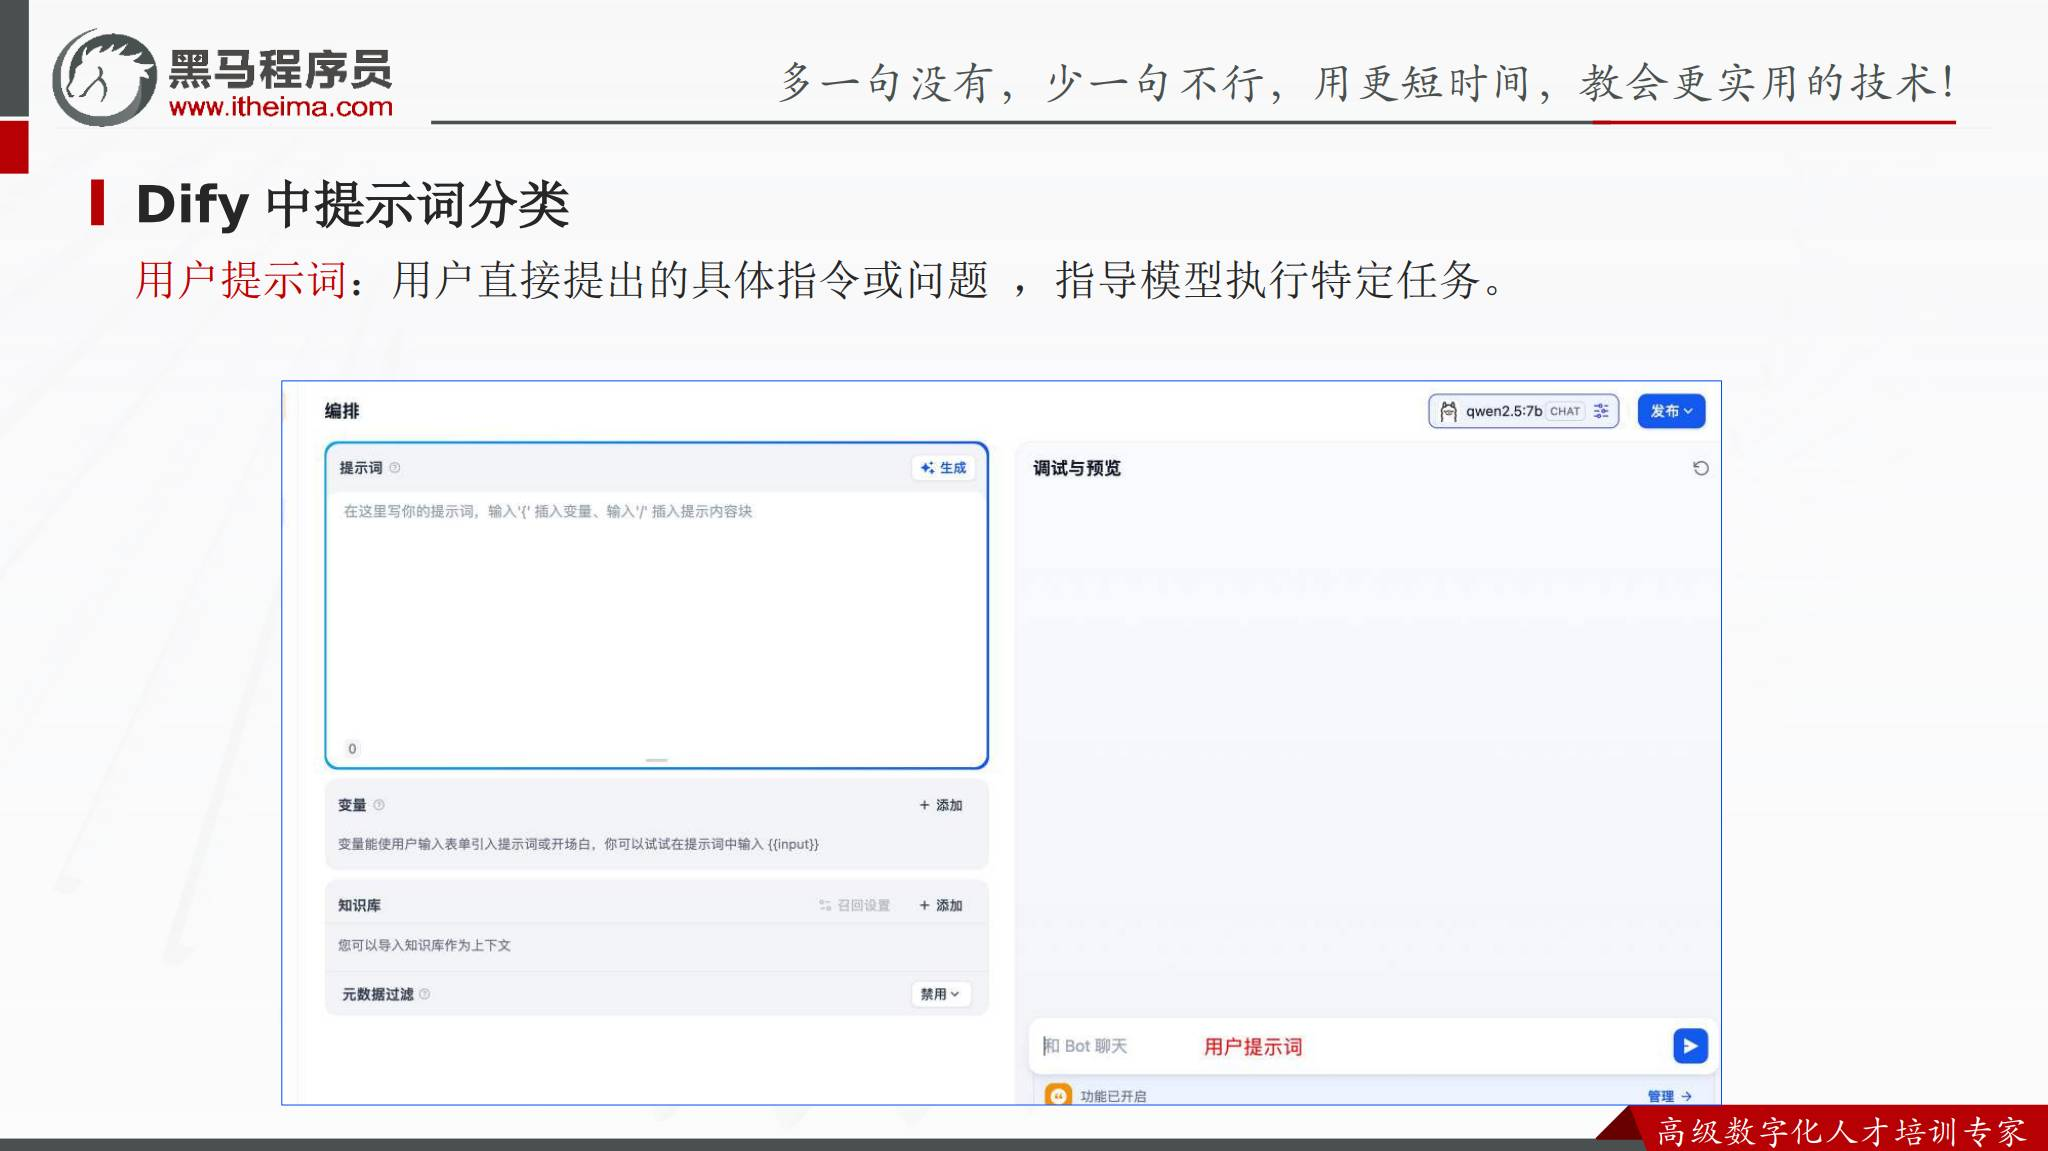

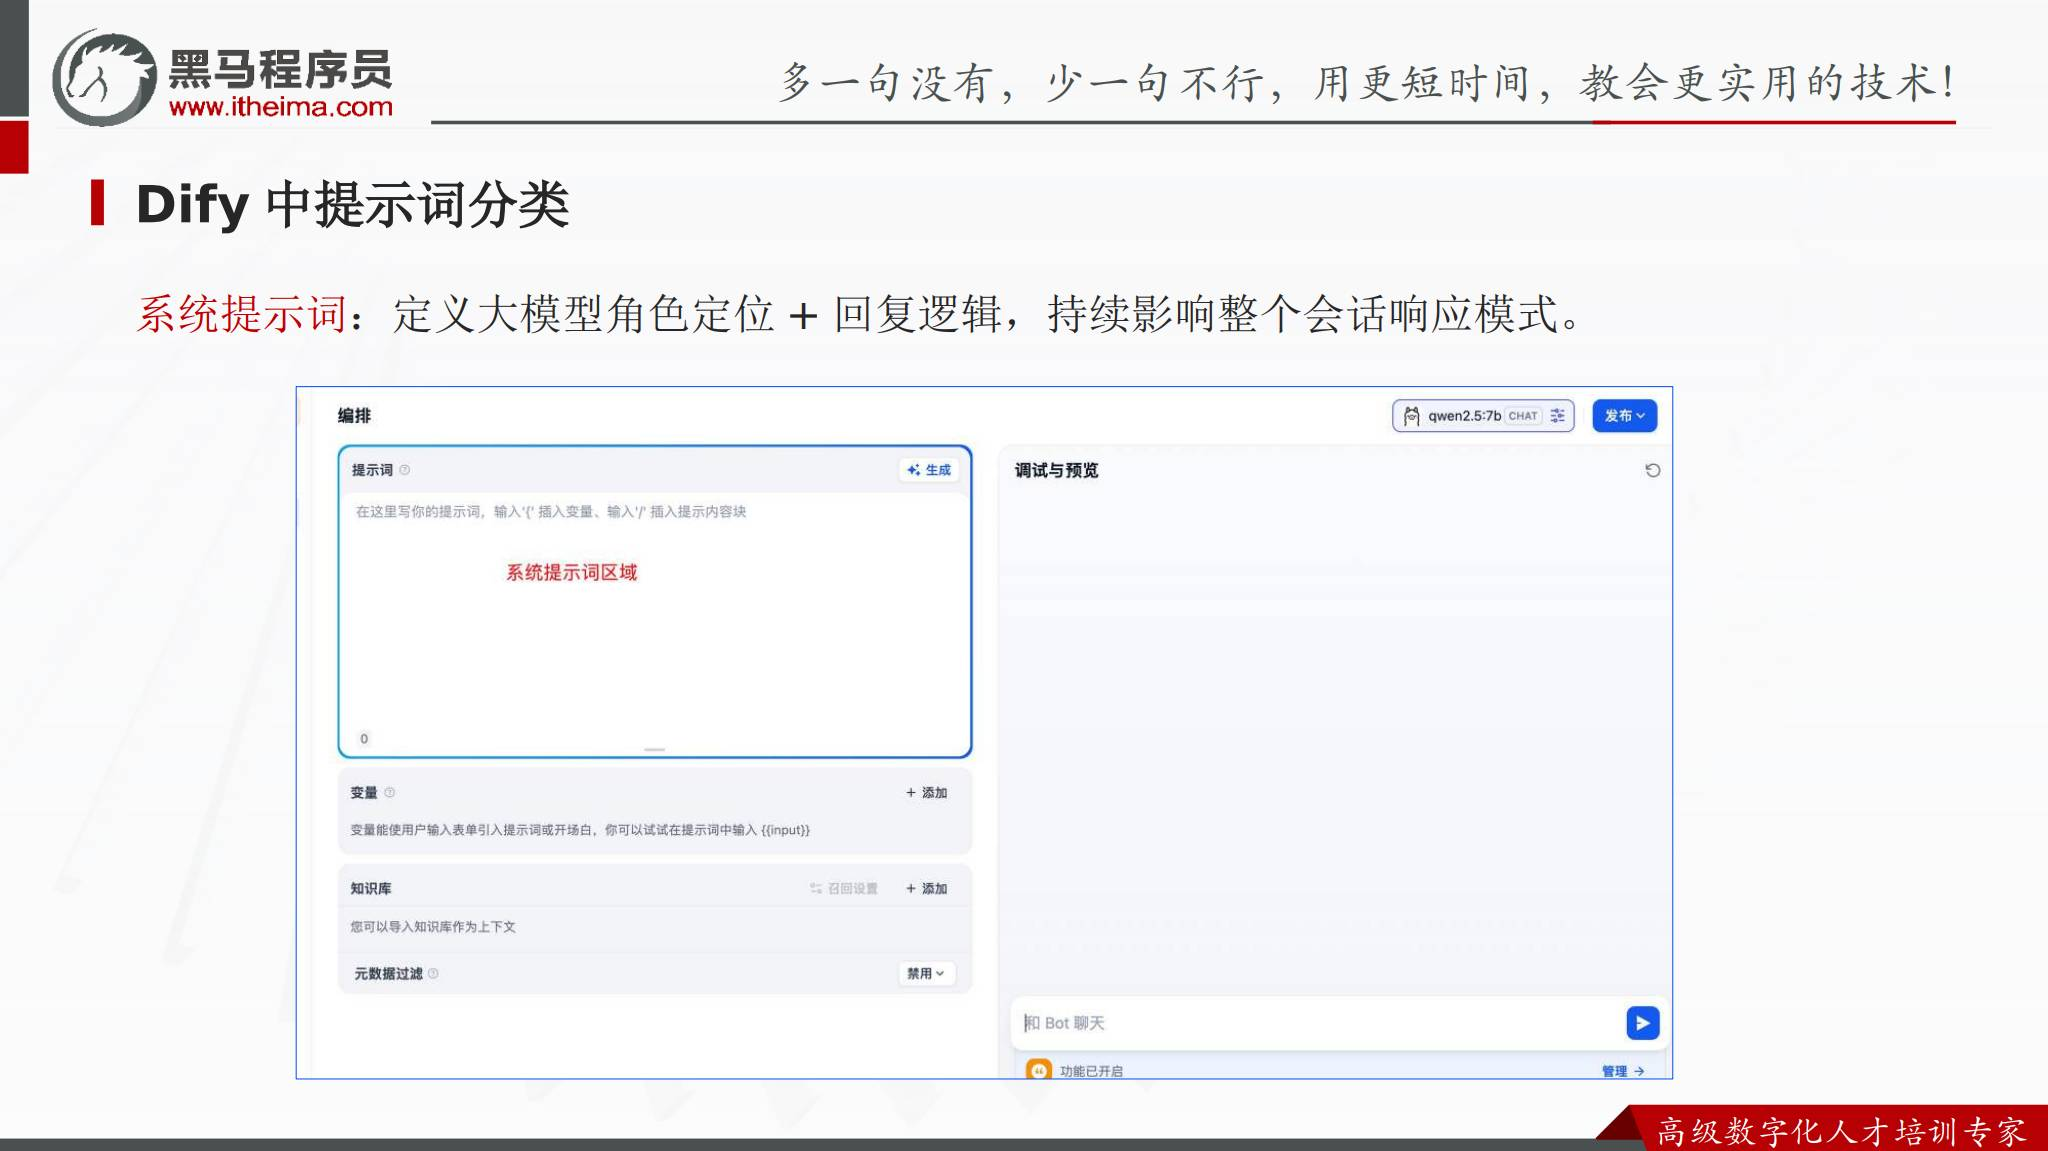


## 10. 在 Dify 中设置和优化提示词

课件给出的实践方式是：先自己编写提示词，再让 AI 大模型帮助优化。实际设置时，可以按下面顺序检查：

1. 在系统提示词中写清角色、任务、边界和输出规则。
2. 在用户提示词中保留用户每次输入的具体问题或材料。
3. 运行几组不同输入，观察模型是否遵守格式和约束。
4. 根据失败结果补充缺少的条件，再重复测试。

提示词的优化不是只替换几个词，而是根据模型实际输出，补齐任务目标、示例、格式或边界。


## 11. 提示词初体验：健康咨询助手

课件用健康咨询助手演示系统提示词和用户提示词的关系：

```text
系统提示词：你是一个心理医生，能够为患者进行心理疾病的诊断
用户提示词：医生，我最近很焦虑
```

这个示例的重点是区分两类提示词，而不是把它作为真实医疗服务方案。实际应用需要明确专业资质、风险边界和人工转介机制，不能仅凭模型回答进行诊断或治疗。

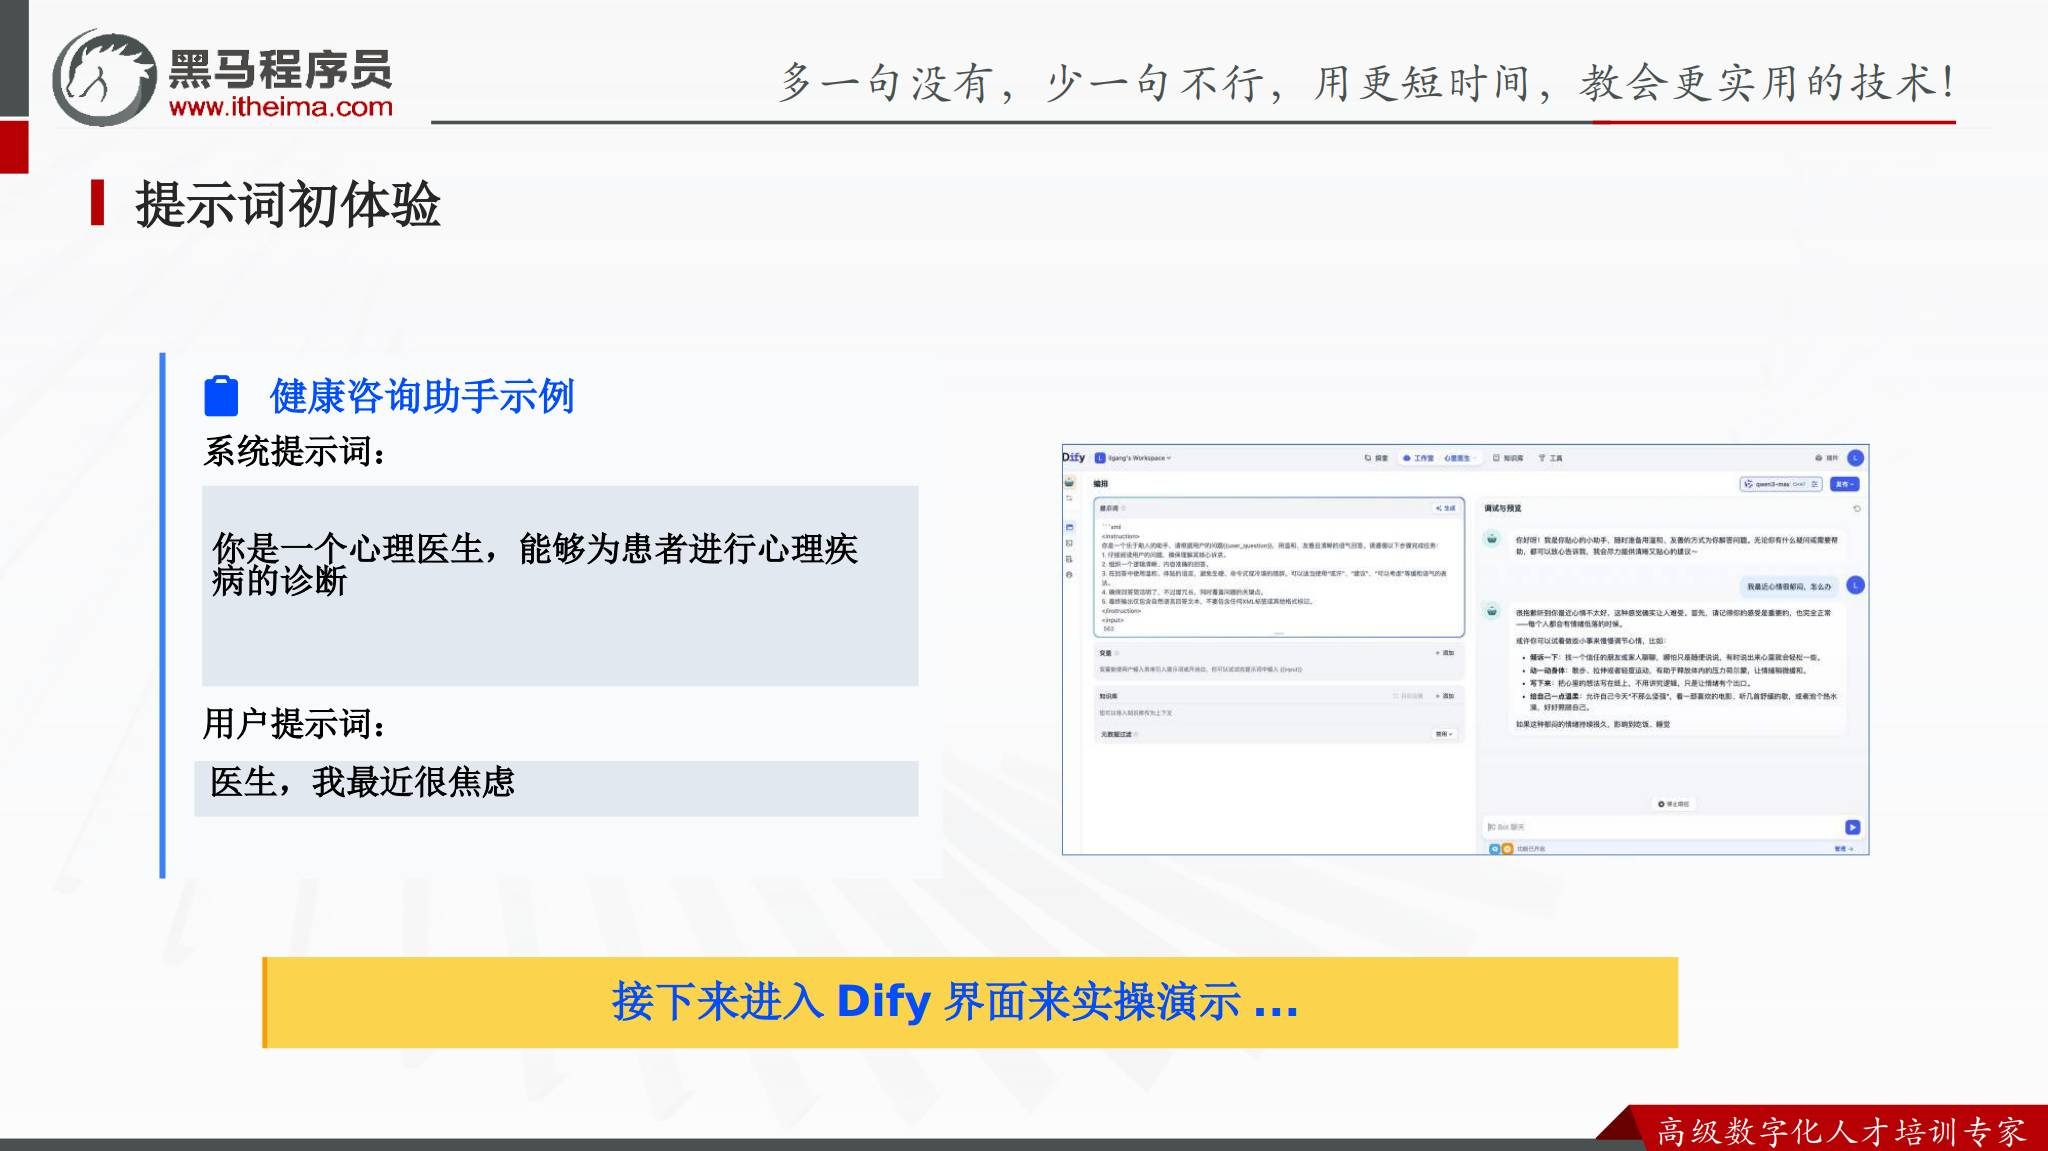


## 12. 第二部分小结

在 Dify 中，系统提示词负责长期的角色和规则，用户提示词负责当前对话的指令和问题。应用开发时可以先写出初版提示词，再利用模型优化，并通过多组输入验证输出是否稳定。


## 13. 实战需求：金融文本信息抽取

本章的实战目标是构建“金融文本信息抽取助手”：用户输入财报内容，助手从文本中提取关键信息。

这个任务适合用提示词工程练习，因为它要求模型同时做到：

- 理解输入文本的业务语境。
- 只提取任务需要的信息。
- 按固定结构输出结果。
- 在原文缺少信息时保持谨慎，不自行补造内容。

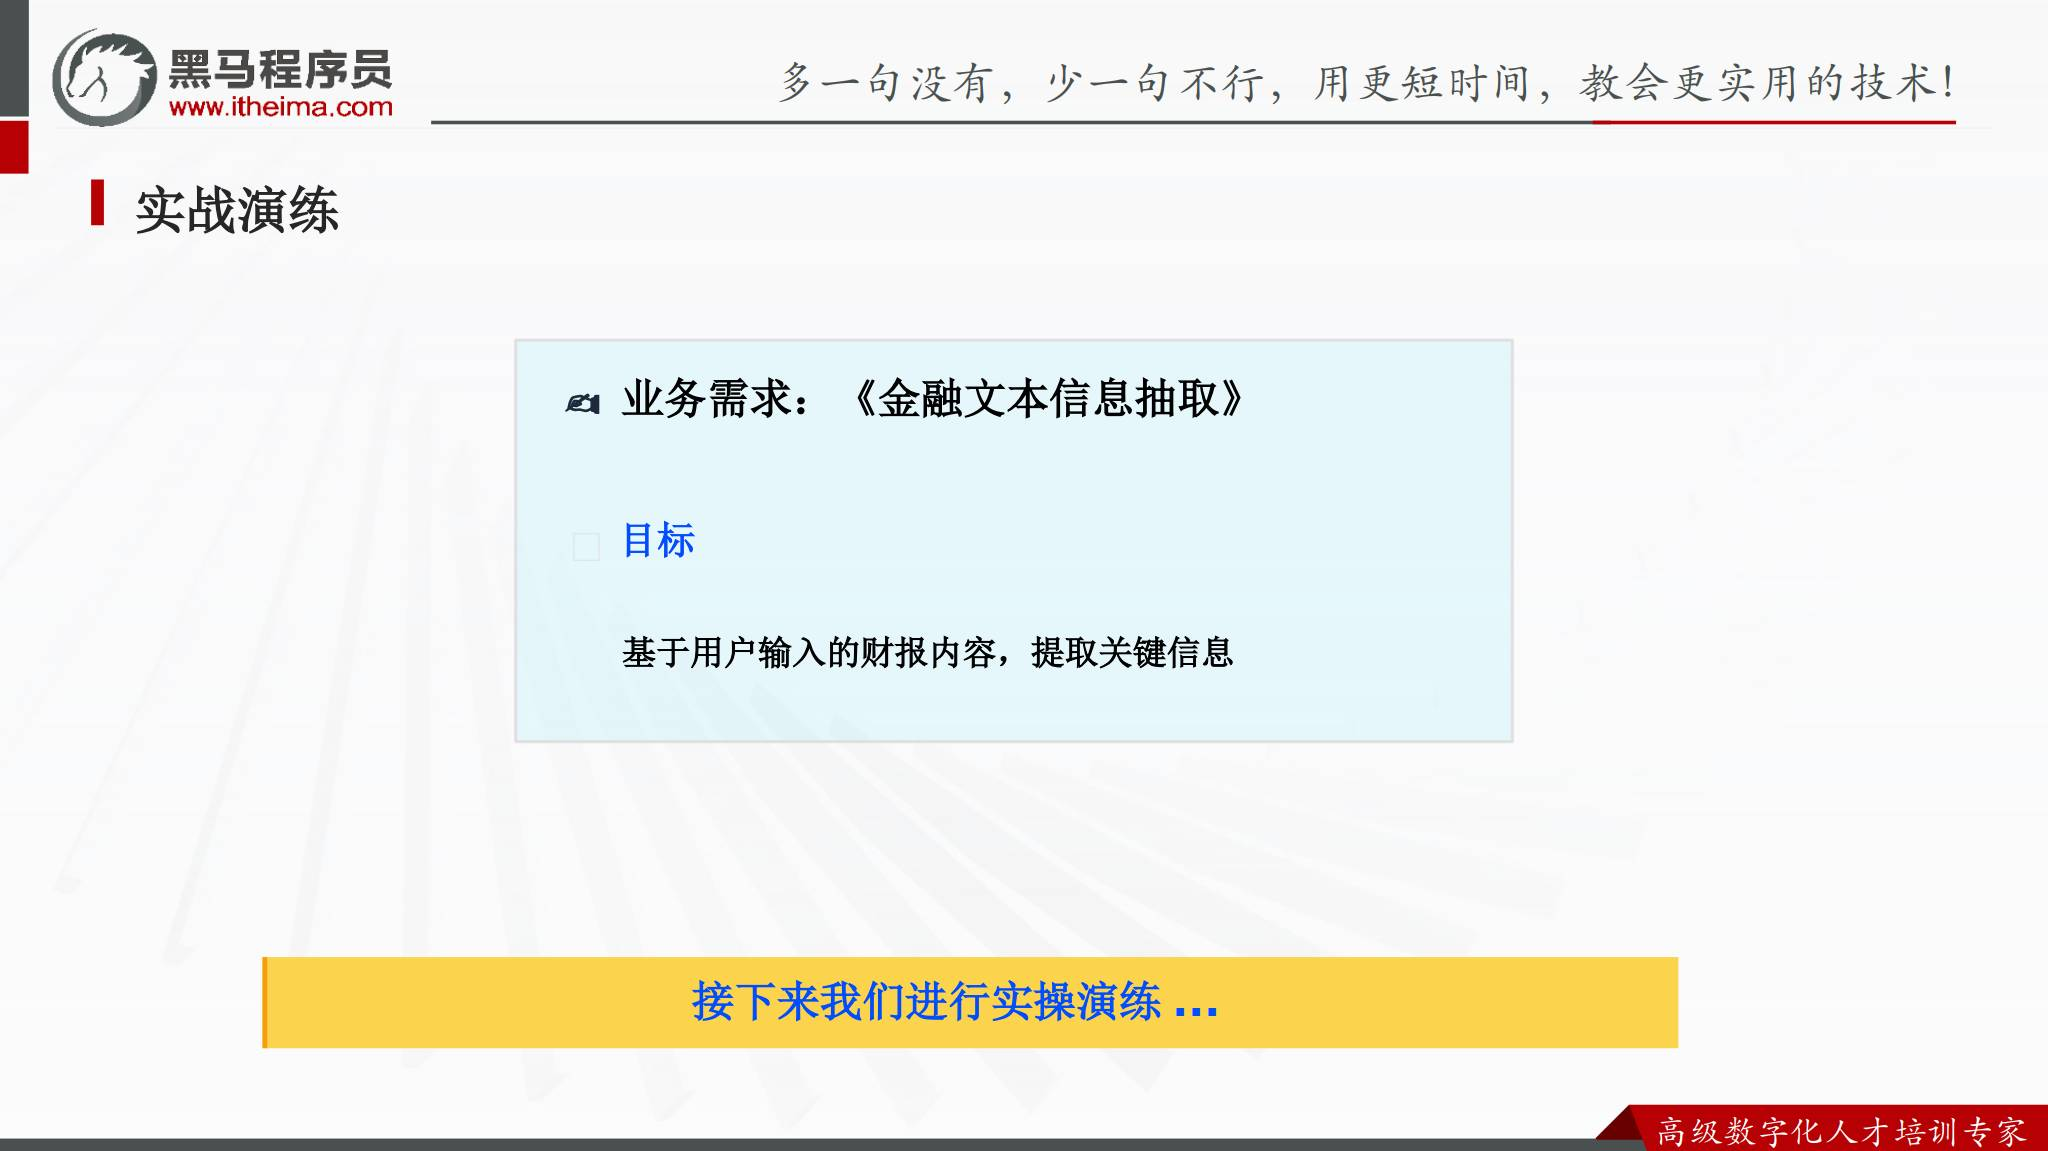


## 14. 规范提示词与不规范提示词

课件从四个方面比较两种提示词：

| 规范提示词 | 不规范提示词 |
| --- | --- |
| 有明确的角色设定 | 指令模糊，例如只说“提取数据” |
| 有具体的目标和任务范围 | 没有说明提取什么、如何判断 |
| 有格式强约束 | 没有规定输出结构 |
| 提供 Few-shot 示例 | 没有示例，完全依赖模型自由发挥 |

Few-shot 示例就是在提示词中给出少量“输入与期望输出”的示例，让模型参照示例理解任务边界和表达方式。金融文本抽取中，示例尤其适合说明字段格式、缺失值处理和数字表达方式。

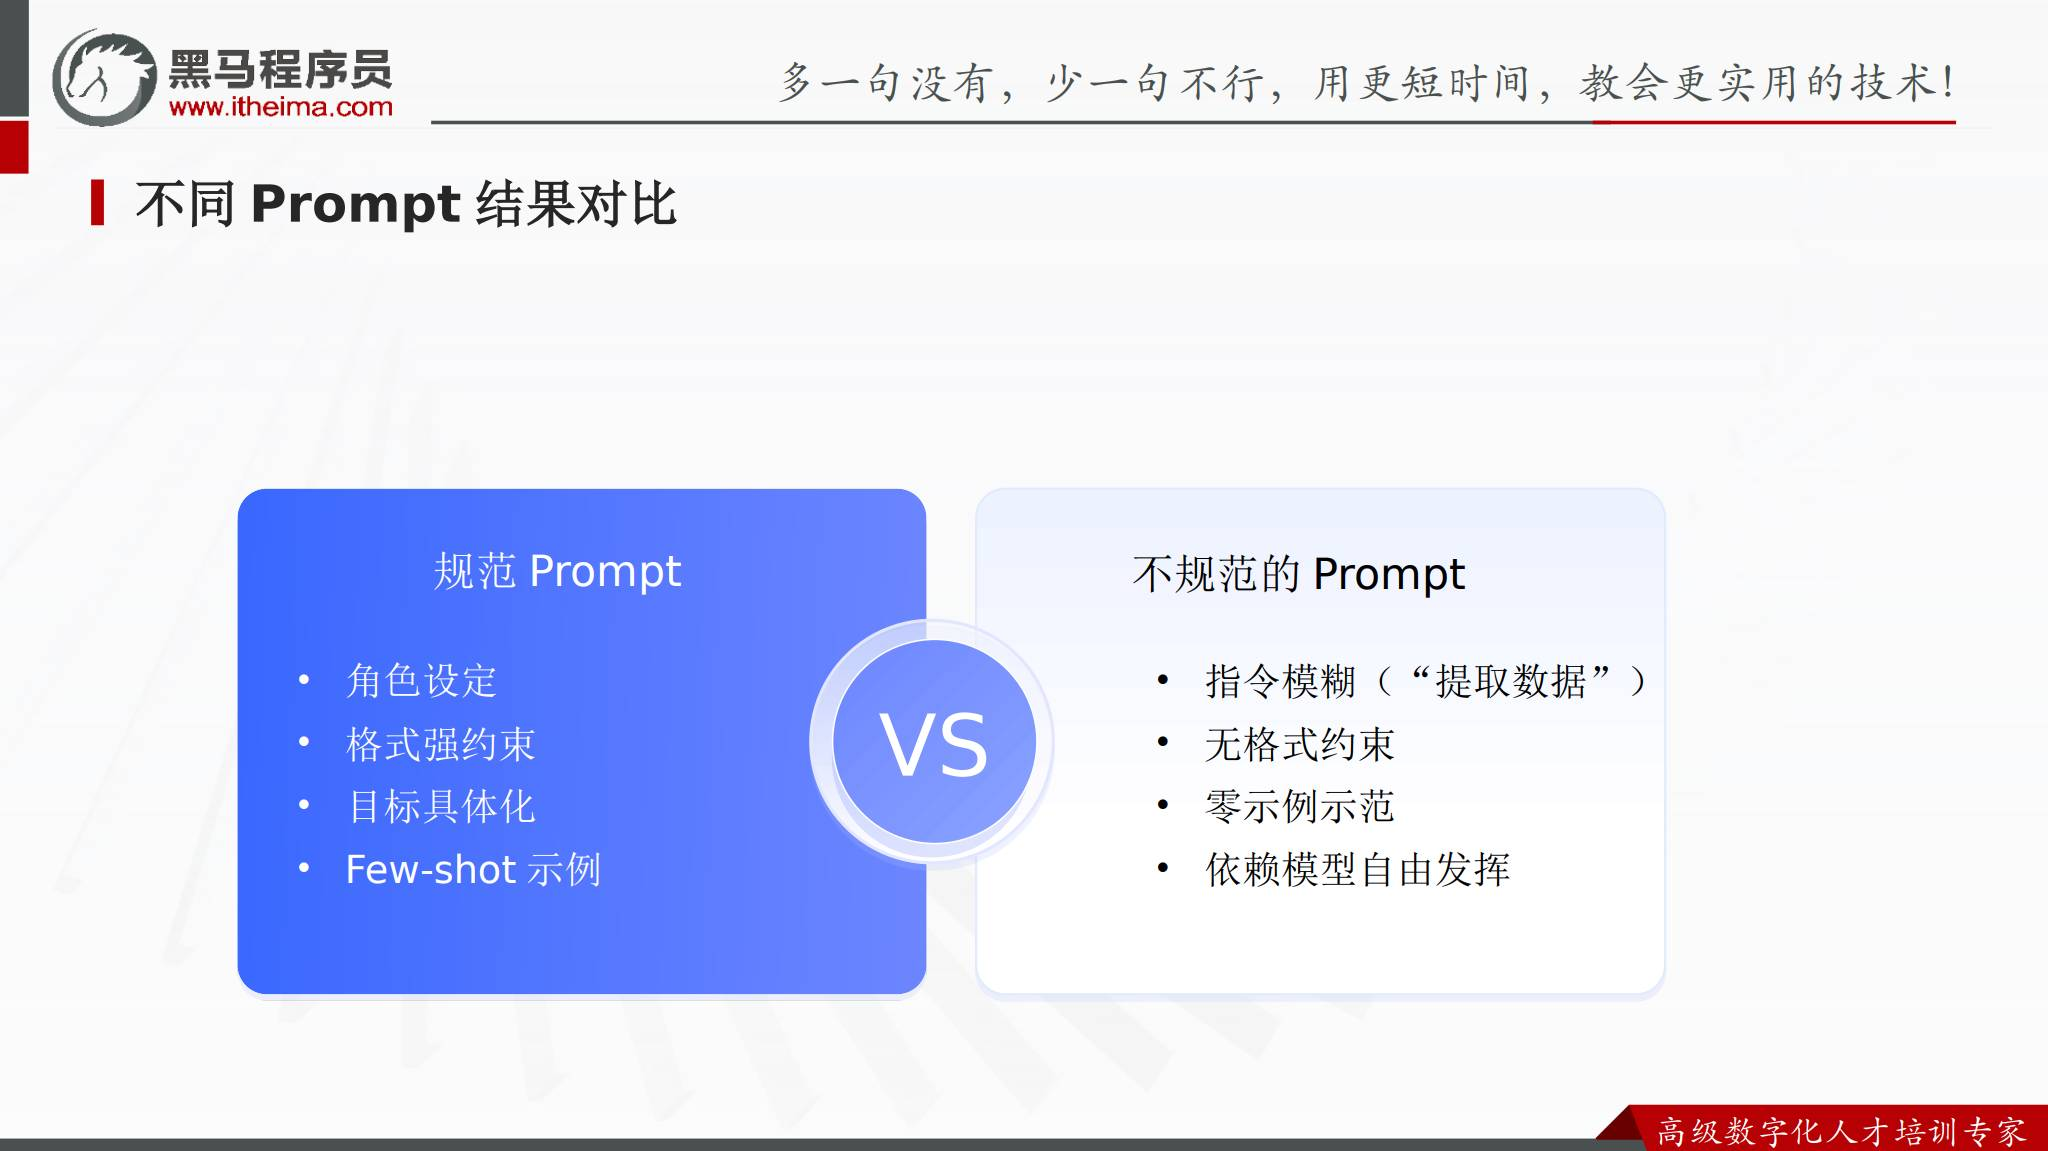


## 15. 实战设计顺序

针对金融文本信息抽取助手，可以按课件的结构化思路设计提示词：

1. 写角色：说明助手负责金融文本信息抽取。
2. 写目标：说明从用户提供的财报内容中提取关键信息。
3. 写边界：只依据输入文本，缺失信息明确标注，不凭空补充。
4. 写格式：规定字段顺序、字段名称和结果表达方式。
5. 加示例：提供一组输入文本和符合要求的输出，帮助模型理解格式。
6. 在 Dify 中测试不同长度和不同写法的财报文本，逐步修正提示词。

这套顺序把业务要求转换为模型可以执行的规则，也方便定位问题是出在角色、目标、约束还是格式。


## 16. 本章小结

标准提示词的核心结构是：**角色 + 目标 + 示例 + 格式**。在此基础上补充约束条件，可以让 Dify 中的模型输出更稳定、更容易检查。

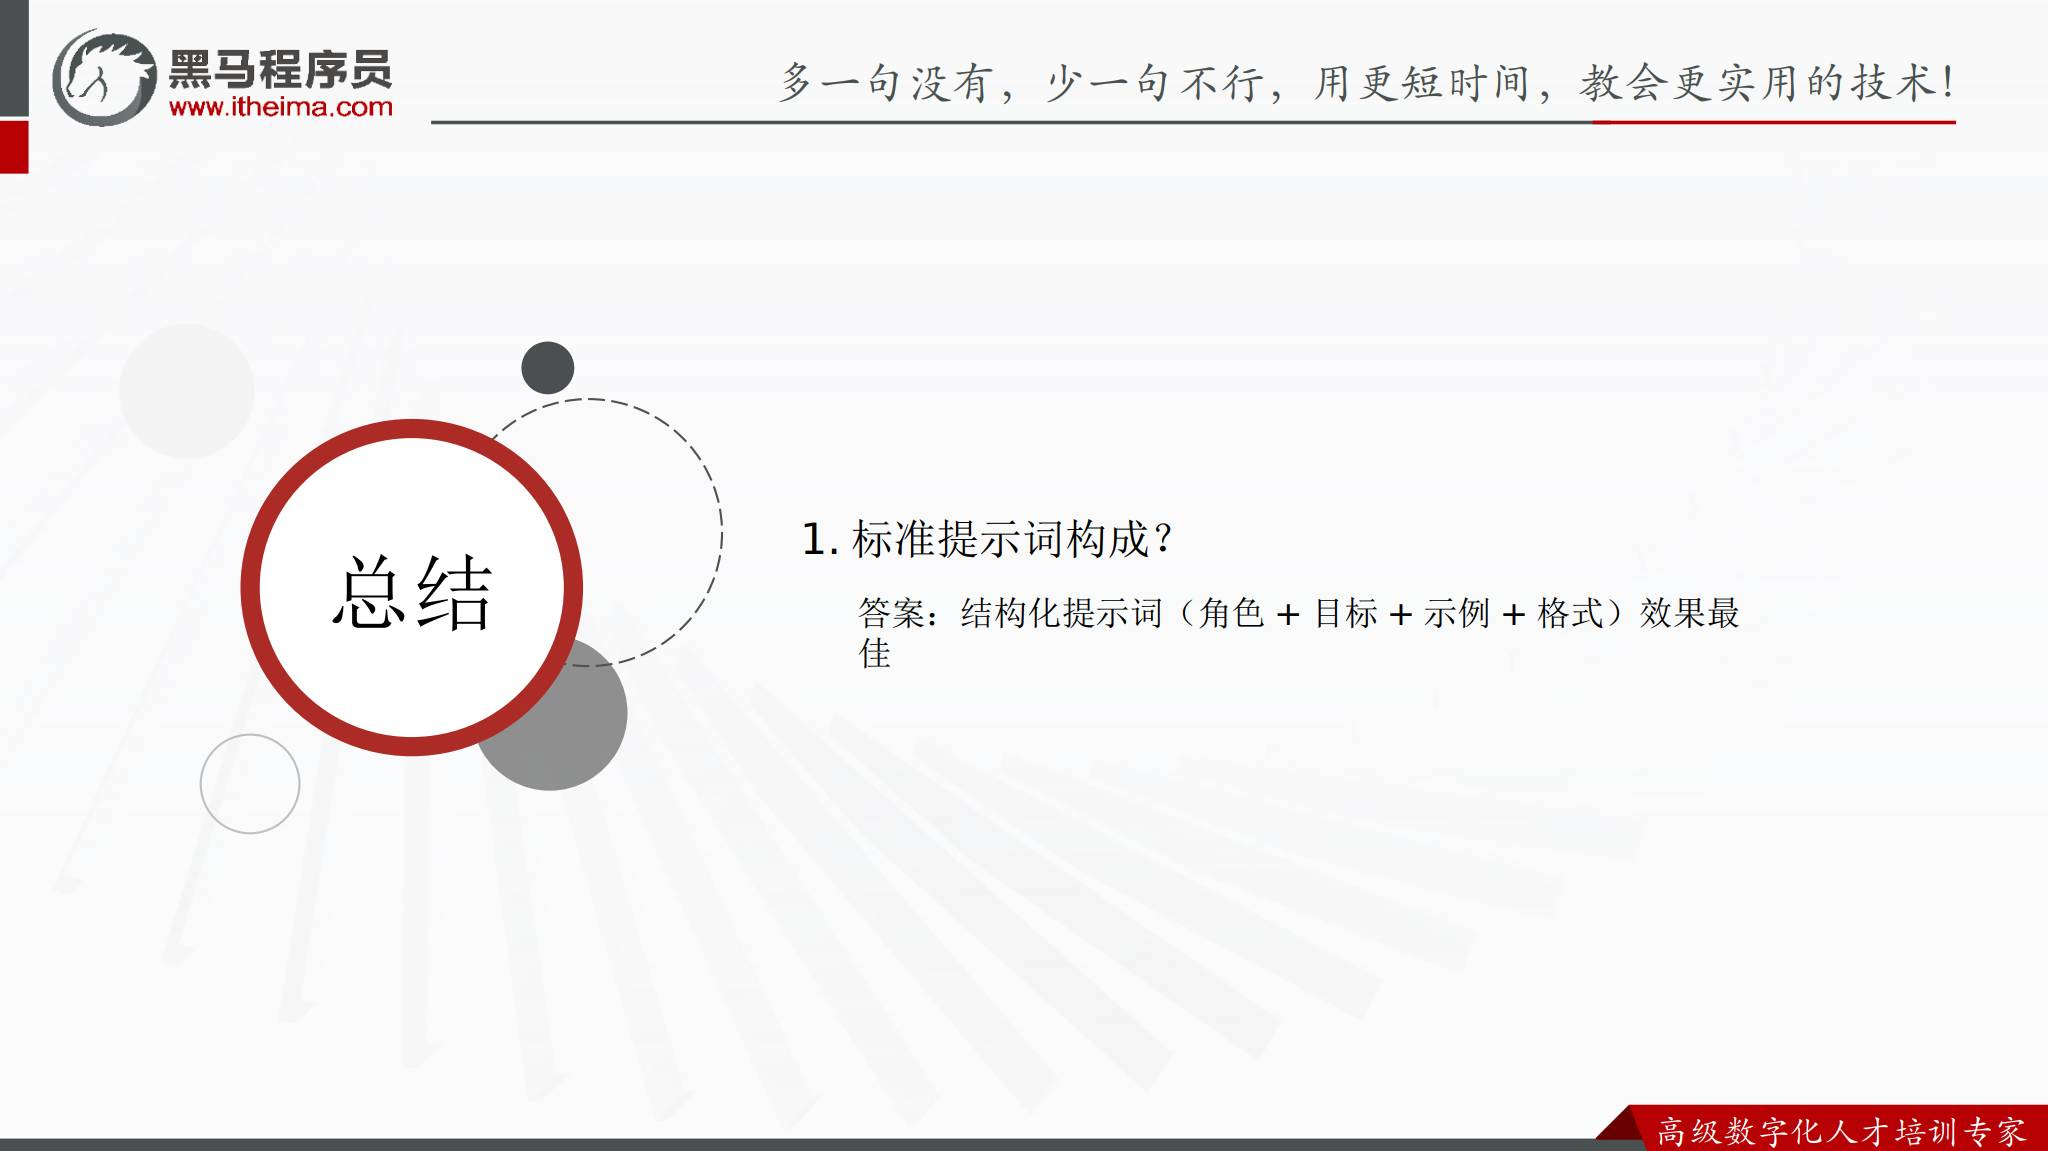


## 17. 资料边界

本篇依据第 3 章课件整理了 Prompt 定义、四个关键要素、Dify 的系统提示词与用户提示词，以及金融文本信息抽取案例。课件对案例给出了需求和设计原则，没有提供完整可复制的金融字段模板，因此本篇保留设计步骤，不虚构课件之外的具体字段或完整业务代码。
